In [13]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/skin-cancer-mnist-ham10000/hmnist_8_8_RGB.csv
/kaggle/input/skin-cancer-mnist-ham10000/hmnist_28_28_RGB.csv
/kaggle/input/skin-cancer-mnist-ham10000/hmnist_8_8_L.csv
/kaggle/input/skin-cancer-mnist-ham10000/hmnist_28_28_L.csv
/kaggle/input/skin-cancer-mnist-ham10000/HAM10000_metadata.csv
/kaggle/input/skin-cancer-mnist-ham10000/HAM10000_images_part_1/ISIC_0028933.jpg
/kaggle/input/skin-cancer-mnist-ham10000/HAM10000_images_part_1/ISIC_0028394.jpg
/kaggle/input/skin-cancer-mnist-ham10000/HAM10000_images_part_1/ISIC_0027799.jpg
/kaggle/input/skin-cancer-mnist-ham10000/HAM10000_images_part_1/ISIC_0028100.jpg
/kaggle/input/skin-cancer-mnist-ham10000/HAM10000_images_part_1/ISIC_0027960.jpg
/kaggle/input/skin-cancer-mnist-ham10000/HAM10000_images_part_1/ISIC_0028872.jpg
/kaggle/input/skin-cancer-mnist-ham10000/HAM10000_images_part_1/ISIC_0026412.jpg
/kaggle/input/skin-cancer-mnist-ham10000/HAM10000_images_part_1/ISIC_0024872.jpg
/kaggle/input/skin-cancer-mnist-ham10000/HAM10000

In [1]:
!pip install grad-cam

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 52.6 MB/s eta 0:00:0000:0100:01
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for grad-cam: filename=grad_cam-1.5.5-py3-none-any.whl size=44285 sha256=a263dcb9a0cb243de144535da88895e8ce06226b4e5a80b6bfaa3236e1d44ead
  Stored in directory: /root/.cache/pip/wheels/fb/3b/09/2afc520f3d69bc26ae6bd87416759c820a3f7d05c1a077bbf6
Successfully built grad-cam


In [22]:
import os
import glob

# Quick check: where am I + are weights present?
print("PWD:", os.getcwd())
print("PTH files (current folder):", glob.glob("*.pth"))

# Also search recursively (useful in Colab/Drive setups)
pth_files = glob.glob("**/*.pth", recursive=True)
print("PTH files (recursive):", len(pth_files))
for p in pth_files[:20]:
    print(" -", p)

PWD: /kaggle/working
PTH files (current folder): ['improved_resnet50_skin.pth', 'improved_inceptionv3_skin.pth', 'improved_efficientnetb0_skin.pth']
PTH files (recursive): 3
 - improved_resnet50_skin.pth
 - improved_inceptionv3_skin.pth
 - improved_efficientnetb0_skin.pth


In [24]:
import torch
import torch.nn as nn
from torchvision import transforms, models
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
import os
import random
from tqdm import tqdm
from sklearn.utils.class_weight import compute_class_weight
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, f1_score, precision_score, recall_score
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image
import warnings
warnings.filterwarnings('ignore')

In [25]:

# Set random seeds for reproducibility
torch.manual_seed(42)
np.random.seed(42)
random.seed(42)

# Constants and Configuration
MELANOMA_CLASS_NAMES = [
    "Melanocytic Nevus",     # label 0
    "Melanoma",              # label 1  
    "Benign Keratosis",      # label 2
    "Basal Cell Carcinoma",  # label 3
    "Actinic Keratoses",     # label 4
    "Vascular Lesion",       # label 5
    "Dermatofibroma"         # label 6
]

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cuda


In [26]:
# Data Transforms
TRAIN_TRANSFORM_224 = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.RandomCrop((224, 224)),
    transforms.RandomRotation(20),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.1),
    transforms.RandomAffine(degrees=0, translate=(0.1, 0.1), scale=(0.9, 1.1)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

TRAIN_TRANSFORM_299 = transforms.Compose([
    transforms.Resize((320, 320)),
    transforms.RandomCrop((299, 299)),
    transforms.RandomRotation(20),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.1),
    transforms.RandomAffine(degrees=0, translate=(0.1, 0.1), scale=(0.9, 1.1)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

VAL_TRANSFORM_224 = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

VAL_TRANSFORM_299 = transforms.Compose([
    transforms.Resize((299, 299)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])


In [28]:
# Data Loading Function
def load_files():
    """Load HAM10000 dataset"""
    TEST_META = '/kaggle/input/skin-cancer-mnist-ham10000/HAM10000_metadata.csv'
    IMG_DIRS = [
        '/kaggle/input/skin-cancer-mnist-ham10000/HAM10000_images_part_1',
        '/kaggle/input/skin-cancer-mnist-ham10000/HAM10000_images_part_2'
    ]
    
    df = pd.read_csv(TEST_META)
    df['image_id'] = df['image_id'] + '.jpg'
    
    image_paths = {}
    for d in IMG_DIRS:
        for fname in os.listdir(d):
            image_paths[fname] = os.path.join(d, fname)
            
    df['image_path'] = df['image_id'].map(image_paths)
    df = df.dropna(subset=['image_path'])
    
    label_names = sorted(np.unique(df['dx']))
    label_map = {name: idx for idx, name in enumerate(label_names)}
    df['label'] = df['dx'].map(label_map)
    
    return df, image_paths, label_names

In [29]:
# Custom Dataset Class
class SkinLesionDataset(Dataset):
    def __init__(self, df, transform=None, augment_minority_classes=False):
        self.df = df.reset_index(drop=True)
        self.transform = transform
        self.augment_minority_classes = augment_minority_classes
        
        if augment_minority_classes:
            self.df = self._augment_minority_classes()

    def _augment_minority_classes(self):
        class_counts = self.df['label'].value_counts()
        minority_threshold = 1000
        minority_classes = class_counts[class_counts < minority_threshold].index
        
        augmented_df = self.df.copy()
        
        for class_label in minority_classes:
            class_samples = self.df[self.df['label'] == class_label]
            replications_needed = minority_threshold // len(class_samples)
            for _ in range(replications_needed - 1):
                augmented_df = pd.concat([augmented_df, class_samples], ignore_index=True)
                
        return augmented_df.sample(frac=1, random_state=42).reset_index(drop=True)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        try:
            row = self.df.iloc[idx]
            image = Image.open(row['image_path']).convert('RGB')
            label = int(row['label'])
            
            if self.transform:
                image = self.transform(image)
            
            return image, label
        except Exception as e:
            print(f"Error loading image at index {idx}: {e}")
            if self.transform:
                black_image = self.transform(Image.new('RGB', (224, 224), (0, 0, 0)))
            else:
                black_image = Image.new('RGB', (224, 224), (0, 0, 0))
            return black_image, 0

In [30]:
# Model Architectures
class ImprovedResNet50(nn.Module):
    def __init__(self, num_classes, pretrained=True, dropout_rate=0.5):
        super().__init__()
        self.backbone = models.resnet50(weights=models.ResNet50_Weights.DEFAULT if pretrained else None)
        num_features = self.backbone.fc.in_features
        self.backbone.fc = nn.Sequential(
            nn.Dropout(dropout_rate),
            nn.Linear(num_features, 512),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout_rate * 0.6),
            nn.Linear(512, num_classes)
        )
    
    def forward(self, x):
        return self.backbone(x)

In [31]:
class ImprovedEfficientNetB0(nn.Module):
    def __init__(self, num_classes, pretrained=True, dropout_rate=0.5):
        super().__init__()
        self.backbone = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT if pretrained else None)
        num_features = self.backbone.classifier[1].in_features
        self.backbone.classifier = nn.Sequential(
            nn.Dropout(dropout_rate),
            nn.Linear(num_features, 512),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout_rate * 0.6),
            nn.Linear(512, num_classes)
        )
    
    def forward(self, x):
        return self.backbone(x)

In [32]:
class ImprovedInceptionV3(nn.Module):
    def __init__(self, num_classes, pretrained=True, dropout_rate=0.5):
        super().__init__()
        self.backbone = models.inception_v3(weights=models.Inception_V3_Weights.DEFAULT if pretrained else None)
        self.backbone.aux_logits = False
        num_features = self.backbone.fc.in_features
        self.backbone.fc = nn.Sequential(
            nn.Dropout(dropout_rate),
            nn.Linear(num_features, 512),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout_rate * 0.6),
            nn.Linear(512, num_classes)
        )
    
    def forward(self, x):
        return self.backbone(x)

In [33]:
# Training Function
def train_model(model, train_loader, val_loader, num_epochs=5, model_name="model"):
    print(f"Starting training for {model_name}")
    print(f"Training samples: {len(train_loader.dataset)}")
    print(f"Validation samples: {len(val_loader.dataset)}")
    
    # Calculate class weights
    y_train = [train_loader.dataset.df.iloc[i]['label'] for i in range(len(train_loader.dataset))]
    class_weights = compute_class_weight(
        'balanced',
        classes=np.unique(y_train),
        y=y_train
    )
    class_weights = torch.FloatTensor(class_weights).to(device)
    
    criterion = nn.CrossEntropyLoss(weight=class_weights)
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-5)
    # scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    #     optimizer, mode='max', factor=0.5, patience=7, verbose=True, min_lr=1e-7
    # )
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='max', factor=0.5, patience=7, min_lr=1e-7
)
    
    best_val_acc = 0.0
    patience_counter = 0
    patience = 15
    train_losses, val_losses, val_accuracies = [], [], []
    
    print(f"Training {model_name}...")
    
    for epoch in range(num_epochs):
        # Training phase
        model.train()
        running_loss = 0.0
        train_correct = 0
        train_total = 0
        
        train_bar = tqdm(train_loader, desc=f'Epoch {epoch+1}/{num_epochs} [Train]')
        for batch_idx, (inputs, labels) in enumerate(train_bar):
            inputs, labels = inputs.to(device), labels.to(device)
            
            if inputs.size(0) == 1:
                continue
            
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            
            running_loss += loss.item()
            _, predicted = torch.max(outputs.data, 1)
            train_total += labels.size(0)
            train_correct += (predicted == labels).sum().item()
            
            train_bar.set_postfix({
                'Loss': f'{running_loss/(batch_idx+1):.4f}',
                'Acc': f'{100.*train_correct/train_total:.2f}%'
            })
        
        train_loss = running_loss / len(train_loader)
        train_acc = 100. * train_correct / train_total
        
        # Validation phase
        model.eval()
        val_loss = 0.0
        val_correct = 0
        val_total = 0
        
        with torch.no_grad():
            val_bar = tqdm(val_loader, desc=f'Epoch {epoch+1}/{num_epochs} [Val]')
            for inputs, labels in val_bar:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels)
                
                val_loss += loss.item()
                _, predicted = torch.max(outputs, 1)
                val_total += labels.size(0)
                val_correct += (predicted == labels).sum().item()
                
                val_bar.set_postfix({
                    'Loss': f'{val_loss/(len(val_bar)+1):.4f}',
                    'Acc': f'{100.*val_correct/val_total:.2f}%'
                })
        
        val_loss = val_loss / len(val_loader)
        val_acc = 100. * val_correct / val_total
        
        train_losses.append(train_loss)
        val_losses.append(val_loss)
        val_accuracies.append(val_acc)
        
        print(f'Epoch {epoch+1}/{num_epochs}:')
        print(f'Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.2f}%')
        print(f'Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.2f}%')
        print('-' * 50)
        
        scheduler.step(val_acc)
        
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            torch.save(model.state_dict(), f'improved_{model_name.lower()}_skin.pth')
            patience_counter = 0
            print(f'New best validation accuracy: {val_acc:.2f}%. Model saved!')
        else:
            patience_counter += 1
        
        if patience_counter >= patience:
            print(f'Early stopping triggered at epoch {epoch+1}')
            break
    
    return train_losses, val_losses, val_accuracies, best_val_acc

# DataLoader creation
def create_dataloader(dataset, batch_size, shuffle=True, num_workers=2):
    return DataLoader(
        dataset, 
        batch_size=batch_size, 
        shuffle=shuffle,
        num_workers=num_workers,
        pin_memory=True,
        drop_last=True
    )


In [34]:
def train_and_save_improved_models():
    """Complete training pipeline for all three models"""
    
    # Load data
    df, image_paths, label_names = load_files()
    
    # Print dataset information
    print(f"Total samples: {len(df)}")
    print("\nClass distribution:")
    class_counts = df['label'].value_counts().sort_index()
    for i, count in enumerate(class_counts):
        print(f"{i}: {MELANOMA_CLASS_NAMES[i]}: {count} samples")
    
    # Prepare data splits
    train_df, val_df = train_test_split(df, test_size=0.2, stratify=df['label'], random_state=42)
    train_df, test_df = train_test_split(train_df, test_size=0.1, stratify=train_df['label'], random_state=42)
    
    print(f"\nTraining set size: {len(train_df)}")
    print(f"Validation set size: {len(val_df)}")
    print(f"Test set size: {len(test_df)}")
    
    num_classes = 7
    batch_size = 16

    models_to_train = [
        {
            'name': 'ResNet50',
            'model_class': ImprovedResNet50,
            'train_transform': TRAIN_TRANSFORM_224,
            'val_transform': VAL_TRANSFORM_224
        },
        {
            'name': 'EfficientNetB0',
            'model_class': ImprovedEfficientNetB0,
            'train_transform': TRAIN_TRANSFORM_224,
            'val_transform': VAL_TRANSFORM_224
        },
        {
            'name': 'InceptionV3',
            'model_class': ImprovedInceptionV3,
            'train_transform': TRAIN_TRANSFORM_299,
            'val_transform': VAL_TRANSFORM_299
        }
    ]
    
    training_results = {}

    # Train each model
    for model_config in models_to_train:
        model_name = model_config['name']
        print(f"\n{'='*60}")
        print(f"Training {model_name}")
        print(f"{'='*60}")
        
        # Create datasets
        train_dataset = SkinLesionDataset(
            train_df, 
            transform=model_config['train_transform'],
            augment_minority_classes=True
        )
        val_dataset = SkinLesionDataset(
            val_df, 
            transform=model_config['val_transform']
        )
        
        # Create data loaders
        # train_loader = create_dataloader(train_dataset, batch_size=batch_size, shuffle=True)
        # val_loader = create_dataloader(val_dataset, batch_size=batch_size, shuffle=False)
        train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True,
                          num_workers=0, pin_memory=True)
        val_loader   = DataLoader(val_dataset, batch_size=batch_size, shuffle=False,
                          num_workers=0, pin_memory=True)
        
        # Initialize model
        model = model_config['model_class'](num_classes=num_classes)
        model = model.to(device)
        
        # Train model
        train_losses, val_losses, val_accuracies, best_val_acc = train_model(
            model, train_loader, val_loader, num_epochs=5, model_name=model_name
        )
        
        training_results[model_name] = {
            'train_losses': train_losses,
            'val_losses': val_losses,
            'val_accuracies': val_accuracies,
            'best_val_acc': best_val_acc
        }
        
        # Plot training curves
        plt.figure(figsize=(15, 5))
        
        plt.subplot(1, 3, 1)
        plt.plot(train_losses, label='Train Loss', color='blue')
        plt.plot(val_losses, label='Val Loss', color='red')
        plt.title(f'{model_name} - Loss Curves')
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(1, 3, 2)
        plt.plot(val_accuracies, label='Val Accuracy', color='green', marker='o')
        plt.title(f'{model_name} - Validation Accuracy')
        plt.xlabel('Epoch')
        plt.ylabel('Accuracy (%)')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(1, 3, 3)
        epochs = range(1, len(train_losses) + 1)
        plt.plot(epochs, train_losses, 'b-', label='Train Loss', linewidth=2)
        plt.plot(epochs, val_losses, 'r-', label='Val Loss', linewidth=2)
        plt.title(f'{model_name} - Training Progress')
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.tight_layout()
        plt.show()
    
    # Summary of results
    print(f"\n{'='*60}")
    print("TRAINING SUMMARY")
    print(f"{'='*60}")
    for model_name, results in training_results.items():
        print(f"{model_name}: Best Val Accuracy = {results['best_val_acc']:.2f}%")
    
    # Save test dataframe for later use
    test_df.to_csv('test_data.csv', index=False)
    
    return training_results, test_df

In [35]:
# Model Loading Functions
models_dict = None

def load_improved_models(num_classes):
    global models_dict
    if models_dict is not None:
        print("Models already loaded, using cached versions.")
        return models_dict
        
    print("Loading improved models...")
    mdict = {}
    
    model_configs = [
        ('ResNet50', ImprovedResNet50, 'improved_resnet50_skin.pth'),
        ('EfficientNetB0', ImprovedEfficientNetB0, 'improved_efficientnetb0_skin.pth'),
        ('InceptionV3', ImprovedInceptionV3, 'improved_inceptionv3_skin.pth')
    ]
    
    for model_name, model_class, filename in model_configs:
        if os.path.exists(filename):
            print(f"Loading {model_name}...")
            model = model_class(num_classes=num_classes)
            model.load_state_dict(torch.load(filename, map_location=device))
            model = model.to(device)
            model.eval()
            mdict[model_name] = model
            print(f"{model_name} loaded successfully!")
        else:
            print(f"Warning: {filename} not found. Train the model first.")
    
    models_dict = mdict
    return mdict

In [15]:
def get_improved_models():
    global models_dict
    if models_dict is None:
        models_dict = load_improved_models(num_classes=7)
    return models_dict

# Utility Functions for Testing
def get_target_layer(model_name, model):
    if model_name == "ResNet50":
        return model.backbone.layer4[-1]
    elif model_name == "EfficientNetB0":
        return model.backbone.features[-1]
    elif model_name == "InceptionV3":
        return model.backbone.Mixed_7c

def get_val_transform(model_name):
    if model_name == "InceptionV3":
        return VAL_TRANSFORM_299
    else:
        return VAL_TRANSFORM_224

def ensemble_predict(models_dict, input_tensor, model_names=None):
    if model_names is None:
        model_names = list(models_dict.keys())
    
    predictions = []
    individual_preds = {}
    
    for model_name in model_names:
        if model_name in models_dict:
            model = models_dict[model_name]
            model.eval()
            with torch.no_grad():
                output = model(input_tensor)
                prob = torch.softmax(output, dim=1)
                predictions.append(prob)
                individual_preds[model_name] = prob.cpu().numpy()[0]
    
    if predictions:
        ensemble_pred = torch.mean(torch.stack(predictions), dim=0)
        return ensemble_pred.cpu().numpy()[0], individual_preds
    else:
        return None, {}

def generate_gradcam_visualization(model, model_name, input_tensor, pred_class_idx, original_image):
    try:
        target_layer = get_target_layer(model_name, model)
        cam = GradCAM(model=model, target_layers=[target_layer])
        targets = [ClassifierOutputTarget(pred_class_idx)]
        
        grayscale_cam = cam(input_tensor=input_tensor, targets=targets)[0]
        
        transform_size = get_val_transform(model_name).transforms[0].size
        if isinstance(transform_size, int):
            rgb_img = np.array(original_image.resize((transform_size, transform_size))).astype(np.float32) / 255.0
        else:
            rgb_img = np.array(original_image.resize(transform_size)).astype(np.float32) / 255.0
        
        visualization = show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True)
        
        return rgb_img, visualization, grayscale_cam
    except Exception as e:
        print(f"Error generating Grad-CAM for {model_name}: {e}")
        return None, None, None

In [36]:
def plot_gradcam_comparison(original_images, gradcam_visualizations, model_names, image_name, predictions, ground_truth):
    n_models = len(model_names)
    if n_models == 0:
        return
    
    fig, axes = plt.subplots(2, n_models + 1, figsize=(4 * (n_models + 1), 8))
    
    if axes.ndim == 1:
        axes = axes.reshape(1, -1)
    
    # Original image display
    if len(original_images) > 0:
        axes[0, 0].imshow(original_images[0])
        axes[0, 0].set_title(f"Original\n{image_name}")
        axes[0, 0].axis('off')
        
        axes[1, 0].text(0.5, 0.5, f"Ground Truth:\n{ground_truth}", 
                       ha='center', va='center', fontsize=12, weight='bold',
                       bbox=dict(boxstyle="round,pad=0.3", facecolor="lightblue"))
        axes[1, 0].axis('off')
    
    # Grad-CAM visualizations
    for i, model_name in enumerate(model_names):
        col_idx = i + 1
        
        if i < len(gradcam_visualizations) and gradcam_visualizations[i] is not None:
            axes[0, col_idx].imshow(gradcam_visualizations[i])
            
            pred_info = predictions.get(model_name, {})
            pred_name = MELANOMA_CLASS_NAMES[pred_info.get('prediction', 0)] if pred_info.get('prediction', 0) < len(MELANOMA_CLASS_NAMES) else "Unknown"
            confidence = pred_info.get('confidence', 0)
            status = "✓" if pred_info.get('correct', False) else "✗"
            
            axes[0, col_idx].set_title(f"{model_name}\nGrad-CAM {status}")
            axes[0, col_idx].axis('off')

            color = "lightgreen" if pred_info.get('correct', False) else "lightcoral"
            axes[1, col_idx].text(0.5, 0.5, f"Prediction:\n{pred_name}\nConfidence: {confidence:.3f}", 
                                 ha='center', va='center', fontsize=10,
                                 bbox=dict(boxstyle="round,pad=0.3", facecolor=color))
            axes[1, col_idx].axis('off')
        else:
            axes[0, col_idx].text(0.5, 0.5, f"Grad-CAM\nError", ha='center', va='center')
            axes[0, col_idx].axis('off')
            axes[1, col_idx].axis('off')
    
    plt.tight_layout()
    plt.show()

In [37]:
# Comprehensive Testing Function
def comprehensive_model_evaluation(test_df=None, num_random_images=10, show_gradcam=True):
    """Comprehensive evaluation with detailed metrics and comparisons"""
    
    # Load models
    models_dict = get_improved_models()
    if not models_dict:
        print("No models found. Please train them first.")
        return
    
    # Load test data
    if test_df is None:
        if os.path.exists('test_data.csv'):
            test_df = pd.read_csv('test_data.csv')
        else:
            df, _, _ = load_files()
            test_df = df.sample(n=min(1000, len(df)), random_state=42)
    
    print(f"\n{'='*80}")
    print(f"COMPREHENSIVE MODEL EVALUATION")
    print(f"{'='*80}")
    print(f"Total test samples: {len(test_df)}")
    print(f"Random visualization samples: {num_random_images}")
    
    # Initialize result storage
    all_predictions = {model_name: [] for model_name in models_dict.keys()}
    all_ground_truth = []
    all_confidences = {model_name: [] for model_name in models_dict.keys()}
    ensemble_predictions = []
    ensemble_confidences = []
    
    # Test on subset for detailed analysis
    random_indices = random.sample(range(len(test_df)), min(num_random_images, len(test_df)))
    detailed_results = []
    
    print(f"\n{'-'*40}")
    print("DETAILED ANALYSIS ON RANDOM SAMPLES")
    print(f"{'-'*40}")
    
    for idx, test_idx in enumerate(random_indices):
        row = test_df.iloc[test_idx]
        img_path = row['image_path']
        gt_label = int(row['label'])
        gt_name = MELANOMA_CLASS_NAMES[gt_label]
        
        print(f"\nImage {idx+1}/{len(random_indices)}: {os.path.basename(img_path)}")
        print(f"Ground Truth: {gt_name}")
        print("-" * 30)
        
        # Load image
        pil_img = Image.open(img_path).convert('RGB')
        
        # Storage for visualization
        individual_predictions = {}
        gradcam_visualizations = []
        original_images = []
        model_names_for_viz = []
        
        # Test each model
        sample_results = {'ground_truth': gt_label, 'image_path': img_path}
        
        for model_name in models_dict.keys():
            model = models_dict[model_name]
            val_transform = get_val_transform(model_name)
            
            input_tensor = val_transform(pil_img).unsqueeze(0).to(device)
            
            with torch.no_grad():
                outputs = model(input_tensor)
                probabilities = torch.softmax(outputs, dim=1)
                pred_class_idx = int(torch.argmax(probabilities, 1).cpu().numpy()[0])
                confidence = float(probabilities[0][pred_class_idx].cpu().numpy())
            
            pred_name = MELANOMA_CLASS_NAMES[pred_class_idx]
            is_correct = pred_class_idx == gt_label
            status = "✓ CORRECT" if is_correct else "✗ WRONG"
            
            print(f"{model_name:15}: {pred_name:20} ({confidence:.3f}) {status}")
            
            # Store results
            individual_predictions[model_name] = {
                'prediction': pred_class_idx,
                'confidence': confidence,
                'correct': is_correct
            }
            
            sample_results[f'{model_name}_pred'] = pred_class_idx
            sample_results[f'{model_name}_conf'] = confidence
            sample_results[f'{model_name}_correct'] = is_correct
            
            # Generate Grad-CAM
            if show_gradcam:
                rgb_img, gradcam_viz, _ = generate_gradcam_visualization(
                    model, model_name, input_tensor, pred_class_idx, pil_img
                )
                
                if gradcam_viz is not None:
                    gradcam_visualizations.append(gradcam_viz)
                    if len(original_images) == 0:
                        original_images.append(rgb_img)
                    model_names_for_viz.append(model_name)
        
        # Ensemble prediction
        input_tensor_ensemble = VAL_TRANSFORM_224(pil_img).unsqueeze(0).to(device)
        ensemble_pred, _ = ensemble_predict(models_dict, input_tensor_ensemble)
        
        if ensemble_pred is not None:
            ensemble_class_idx = int(np.argmax(ensemble_pred))
            ensemble_confidence = float(ensemble_pred[ensemble_class_idx])
            ensemble_name = MELANOMA_CLASS_NAMES[ensemble_class_idx]
            ensemble_correct = ensemble_class_idx == gt_label
            ensemble_status = "✓ CORRECT" if ensemble_correct else "✗ WRONG"
            
            print(f"{'Ensemble':15}: {ensemble_name:20} ({ensemble_confidence:.3f}) {ensemble_status}")
            
            sample_results['ensemble_pred'] = ensemble_class_idx
            sample_results['ensemble_conf'] = ensemble_confidence
            sample_results['ensemble_correct'] = ensemble_correct
        
        detailed_results.append(sample_results)
        
        # Display Grad-CAM visualizations
        if show_gradcam and gradcam_visualizations:
            plot_gradcam_comparison(
                original_images, gradcam_visualizations, model_names_for_viz,
                os.path.basename(img_path), individual_predictions, gt_name
            )
    
    # Comprehensive evaluation on full test set
    print(f"\n{'-'*40}")
    print("COMPREHENSIVE EVALUATION ON FULL TEST SET")
    print(f"{'-'*40}")
    
    for idx, row in tqdm(test_df.iterrows(), total=len(test_df), desc="Evaluating"):
        try:
            img_path = row['image_path']
            gt_label = int(row['label'])
            pil_img = Image.open(img_path).convert('RGB')
            
            all_ground_truth.append(gt_label)
            
            # Test each model
            for model_name in models_dict.keys():
                model = models_dict[model_name]
                val_transform = get_val_transform(model_name)
                
                input_tensor = val_transform(pil_img).unsqueeze(0).to(device)
                
                with torch.no_grad():
                    outputs = model(input_tensor)
                    probabilities = torch.softmax(outputs, dim=1)
                    pred_class_idx = int(torch.argmax(probabilities, 1).cpu().numpy()[0])
                    confidence = float(probabilities[0][pred_class_idx].cpu().numpy())
                
                all_predictions[model_name].append(pred_class_idx)
                all_confidences[model_name].append(confidence)
            
            # Ensemble prediction
            input_tensor_ensemble = VAL_TRANSFORM_224(pil_img).unsqueeze(0).to(device)
            ensemble_pred, _ = ensemble_predict(models_dict, input_tensor_ensemble)
            
            if ensemble_pred is not None:
                ensemble_class_idx = int(np.argmax(ensemble_pred))
                ensemble_confidence = float(ensemble_pred[ensemble_class_idx])
                ensemble_predictions.append(ensemble_class_idx)
                ensemble_confidences.append(ensemble_confidence)
            
        except Exception as e:
            print(f"Error processing image {idx}: {e}")
            continue
    
    # Calculate comprehensive metrics
    print(f"\n{'='*80}")
    print("COMPREHENSIVE PERFORMANCE METRICS")
    print(f"{'='*80}")
    
    results_summary = {}
    
    # Individual model metrics
    for model_name in models_dict.keys():
        if len(all_predictions[model_name]) > 0:
            accuracy = np.mean(np.array(all_predictions[model_name]) == np.array(all_ground_truth)) * 100
            precision = precision_score(all_ground_truth, all_predictions[model_name], average='weighted') * 100
            recall = recall_score(all_ground_truth, all_predictions[model_name], average='weighted') * 100
            f1 = f1_score(all_ground_truth, all_predictions[model_name], average='weighted') * 100
            avg_confidence = np.mean(all_confidences[model_name]) * 100
            
            results_summary[model_name] = {
                'accuracy': accuracy,
                'precision': precision,
                'recall': recall,
                'f1_score': f1,
                'avg_confidence': avg_confidence
            }
            
            print(f"\n{model_name} Performance:")
            print(f"  Accuracy:     {accuracy:.2f}%")
            print(f"  Precision:    {precision:.2f}%")
            print(f"  Recall:       {recall:.2f}%")
            print(f"  F1-Score:     {f1:.2f}%")
            print(f"  Avg Conf:     {avg_confidence:.2f}%")
    
    # Ensemble metrics
    if len(ensemble_predictions) > 0:
        ensemble_accuracy = np.mean(np.array(ensemble_predictions) == np.array(all_ground_truth)) * 100
        ensemble_precision = precision_score(all_ground_truth, ensemble_predictions, average='weighted') * 100
        ensemble_recall = recall_score(all_ground_truth, ensemble_predictions, average='weighted') * 100
        ensemble_f1 = f1_score(all_ground_truth, ensemble_predictions, average='weighted') * 100
        ensemble_avg_confidence = np.mean(ensemble_confidences) * 100
        
        results_summary['Ensemble'] = {
            'accuracy': ensemble_accuracy,
            'precision': ensemble_precision,
            'recall': ensemble_recall,
            'f1_score': ensemble_f1,
            'avg_confidence': ensemble_avg_confidence
        }
        
        print(f"\nEnsemble Performance:")
        print(f"  Accuracy:     {ensemble_accuracy:.2f}%")
        print(f"  Precision:    {ensemble_precision:.2f}%")
        print(f"  Recall:       {ensemble_recall:.2f}%")
        print(f"  F1-Score:     {ensemble_f1:.2f}%")
        print(f"  Avg Conf:     {ensemble_avg_confidence:.2f}%")
    
    # Performance comparison visualization
    plt.figure(figsize=(20, 12))
    
    # Accuracy comparison
    plt.subplot(2, 3, 1)
    models = list(results_summary.keys())
    accuracies = [results_summary[m]['accuracy'] for m in models]
    colors = plt.cm.Set3(np.linspace(0, 1, len(models)))
    
    bars = plt.bar(models, accuracies, color=colors)
    plt.title('Model Accuracy Comparison', fontsize=14, weight='bold')
    plt.ylabel('Accuracy (%)')
    plt.xticks(rotation=45)
    
    # Add value labels on bars
    for bar, acc in zip(bars, accuracies):
        plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5, 
                f'{acc:.1f}%', ha='center', va='bottom', fontweight='bold')
    
    plt.grid(True, alpha=0.3)
    
    # F1-Score comparison
    plt.subplot(2, 3, 2)
    f1_scores = [results_summary[m]['f1_score'] for m in models]
    bars = plt.bar(models, f1_scores, color=colors)
    plt.title('Model F1-Score Comparison', fontsize=14, weight='bold')
    plt.ylabel('F1-Score (%)')
    plt.xticks(rotation=45)
    
    for bar, f1 in zip(bars, f1_scores):
        plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5, 
                f'{f1:.1f}%', ha='center', va='bottom', fontweight='bold')
    
    plt.grid(True, alpha=0.3)
    
    # Precision vs Recall
    plt.subplot(2, 3, 3)
    precisions = [results_summary[m]['precision'] for m in models]
    recalls = [results_summary[m]['recall'] for m in models]
    
    for i, model in enumerate(models):
        plt.scatter(recalls[i], precisions[i], s=200, c=[colors[i]], 
                   label=model, alpha=0.7, edgecolors='black')
        plt.annotate(model, (recalls[i], precisions[i]), 
                    xytext=(5, 5), textcoords='offset points', fontsize=10)
    
    plt.title('Precision vs Recall', fontsize=14, weight='bold')
    plt.xlabel('Recall (%)')
    plt.ylabel('Precision (%)')
    plt.grid(True, alpha=0.3)
    plt.legend()
    
    # Confidence distribution
    plt.subplot(2, 3, 4)
    conf_data = []
    conf_labels = []
    for model_name in models_dict.keys():
        if len(all_confidences[model_name]) > 0:
            conf_data.append(np.array(all_confidences[model_name]) * 100)
            conf_labels.append(model_name)
    
    if ensemble_confidences:
        conf_data.append(np.array(ensemble_confidences) * 100)
        conf_labels.append('Ensemble')
    
    plt.boxplot(conf_data, labels=conf_labels)
    plt.title('Confidence Distribution', fontsize=14, weight='bold')
    plt.ylabel('Confidence (%)')
    plt.xticks(rotation=45)
    plt.grid(True, alpha=0.3)
    
    # Overall metrics radar chart
    plt.subplot(2, 3, 5)
    metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
    
    angles = np.linspace(0, 2*np.pi, len(metrics), endpoint=False).tolist()
    angles += angles[:1]  # Complete the circle
    
    for i, model in enumerate(models):
        values = [
            results_summary[model]['accuracy'],
            results_summary[model]['precision'], 
            results_summary[model]['recall'],
            results_summary[model]['f1_score']
        ]
        values += values[:1]  # Complete the circle
        
        plt.plot(angles, values, 'o-', linewidth=2, label=model, color=colors[i])
        plt.fill(angles, values, alpha=0.1, color=colors[i])
    
    plt.xticks(angles[:-1], metrics)
    plt.ylim(0, 100)
    plt.title('Overall Performance Radar', fontsize=14, weight='bold')
    plt.legend()
    plt.grid(True, alpha=0.3)
    
    # Class-wise performance heatmap
    plt.subplot(2, 3, 6)
    
    # Create confusion matrix for best performing model
    best_model = max(results_summary.keys(), key=lambda x: results_summary[x]['accuracy'])
    if best_model == 'Ensemble':
        cm = confusion_matrix(all_ground_truth, ensemble_predictions)
    else:
        cm = confusion_matrix(all_ground_truth, all_predictions[best_model])
    
    # Normalize confusion matrix
    cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis] * 100
    
    sns.heatmap(cm_normalized, annot=True, fmt='.1f', cmap='Blues',
                xticklabels=[name[:15] for name in MELANOMA_CLASS_NAMES],
                yticklabels=[name[:15] for name in MELANOMA_CLASS_NAMES])
    plt.title(f'Confusion Matrix - {best_model}', fontsize=14, weight='bold')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    
    plt.tight_layout()
    plt.show()
    
    # Detailed classification report
    print(f"\n{'='*80}")
    print(f"DETAILED CLASSIFICATION REPORT - BEST MODEL ({best_model})")
    print(f"{'='*80}")
    
    if best_model == 'Ensemble':
        report = classification_report(all_ground_truth, ensemble_predictions, 
                                     target_names=MELANOMA_CLASS_NAMES, digits=3)
    else:
        report = classification_report(all_ground_truth, all_predictions[best_model], 
                                     target_names=MELANOMA_CLASS_NAMES, digits=3)
    print(report)
    
    # Summary table
    print(f"\n{'='*80}")
    print("FINAL PERFORMANCE SUMMARY")
    print(f"{'='*80}")
    print(f"{'Model':<15} {'Accuracy':<10} {'Precision':<11} {'Recall':<8} {'F1-Score':<9} {'Avg Conf':<9}")
    print("-" * 80)
    
    for model_name, metrics in results_summary.items():
        print(f"{model_name:<15} {metrics['accuracy']:<10.2f} {metrics['precision']:<11.2f} "
              f"{metrics['recall']:<8.2f} {metrics['f1_score']:<9.2f} {metrics['avg_confidence']:<9.2f}")
    
    print(f"\nBest performing model: {best_model} with {results_summary[best_model]['accuracy']:.2f}% accuracy")
    
    return results_summary, detailed_results


Total samples: 10015

Class distribution:
0: Melanocytic Nevus: 327 samples
1: Melanoma: 514 samples
2: Benign Keratosis: 1099 samples
3: Basal Cell Carcinoma: 115 samples
4: Actinic Keratoses: 1113 samples
5: Vascular Lesion: 6705 samples
6: Dermatofibroma: 142 samples

Training set size: 7210
Validation set size: 2003
Test set size: 802

Training ResNet50
Starting training for ResNet50
Training samples: 10017
Validation samples: 2003
Training ResNet50...


Epoch 2/5 [Val]: 100%|██████████| 126/126 [00:29<00:00,  4.34it/s, Loss=1.2155, Acc=74.39%]


Epoch 2/5:
Train Loss: 0.7020, Train Acc: 74.33%
Val Loss: 1.2251, Val Acc: 74.39%
--------------------------------------------------
New best validation accuracy: 74.39%. Model saved!


Epoch 3/5 [Val]: 100%|██████████| 126/126 [00:28<00:00,  4.42it/s, Loss=0.8109, Acc=80.58%]


Epoch 3/5:
Train Loss: 0.5826, Train Acc: 77.74%
Val Loss: 0.8174, Val Acc: 80.58%
--------------------------------------------------
New best validation accuracy: 80.58%. Model saved!


Epoch 4/5 [Val]: 100%|██████████| 126/126 [00:28<00:00,  4.46it/s, Loss=0.8124, Acc=78.28%]


Epoch 4/5:
Train Loss: 0.5021, Train Acc: 81.32%
Val Loss: 0.8188, Val Acc: 78.28%
--------------------------------------------------


Epoch 5/5 [Val]: 100%|██████████| 126/126 [00:28<00:00,  4.37it/s, Loss=0.7789, Acc=80.13%]


Epoch 5/5:
Train Loss: 0.4374, Train Acc: 83.38%
Val Loss: 0.7851, Val Acc: 80.13%
--------------------------------------------------


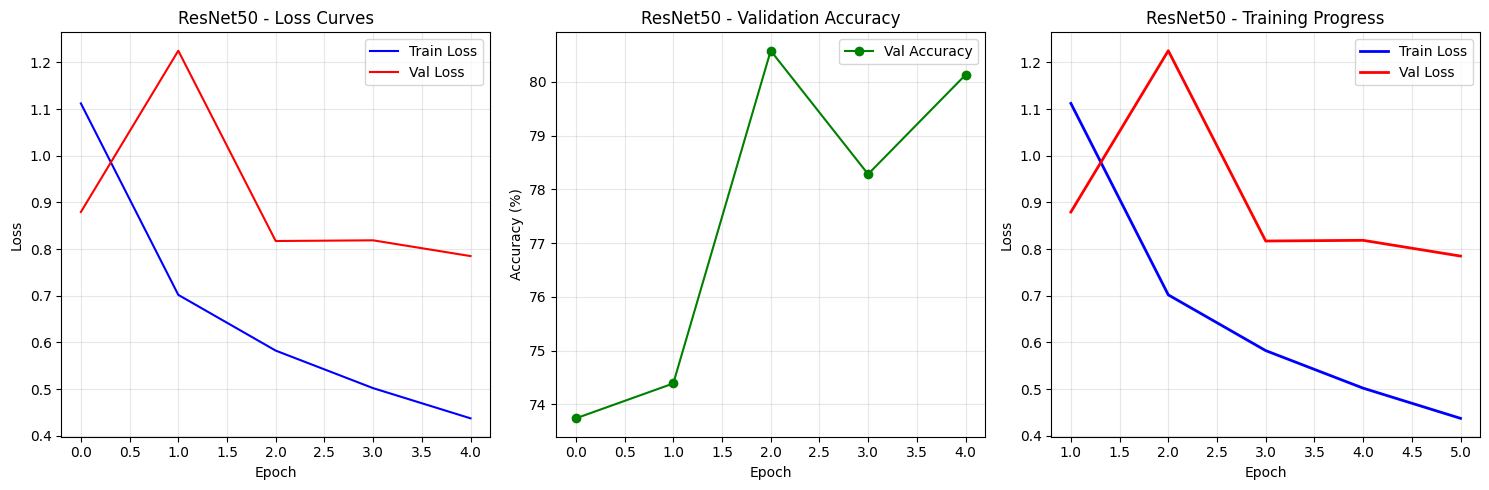


Training EfficientNetB0
Starting training for EfficientNetB0
Training samples: 10017
Validation samples: 2003
Training EfficientNetB0...


Epoch 1/5 [Val]: 100%|██████████| 126/126 [00:24<00:00,  5.14it/s, Loss=0.9203, Acc=69.55%]


Epoch 1/5:
Train Loss: 1.1637, Train Acc: 59.77%
Val Loss: 0.9276, Val Acc: 69.55%
--------------------------------------------------
New best validation accuracy: 69.55%. Model saved!


Epoch 2/5 [Val]: 100%|██████████| 126/126 [00:23<00:00,  5.33it/s, Loss=0.7675, Acc=75.09%]


Epoch 2/5:
Train Loss: 0.7145, Train Acc: 73.57%
Val Loss: 0.7736, Val Acc: 75.09%
--------------------------------------------------
New best validation accuracy: 75.09%. Model saved!


Epoch 3/5 [Val]: 100%|██████████| 126/126 [00:24<00:00,  5.07it/s, Loss=0.7981, Acc=74.49%]


Epoch 3/5:
Train Loss: 0.6037, Train Acc: 75.70%
Val Loss: 0.8045, Val Acc: 74.49%
--------------------------------------------------


Epoch 4/5 [Val]: 100%|██████████| 126/126 [00:23<00:00,  5.30it/s, Loss=0.7711, Acc=76.83%]


Epoch 4/5:
Train Loss: 0.5405, Train Acc: 78.76%
Val Loss: 0.7772, Val Acc: 76.83%
--------------------------------------------------
New best validation accuracy: 76.83%. Model saved!


Epoch 5/5 [Val]: 100%|██████████| 126/126 [00:23<00:00,  5.28it/s, Loss=0.7426, Acc=82.98%]


Epoch 5/5:
Train Loss: 0.4635, Train Acc: 81.43%
Val Loss: 0.7485, Val Acc: 82.98%
--------------------------------------------------
New best validation accuracy: 82.98%. Model saved!


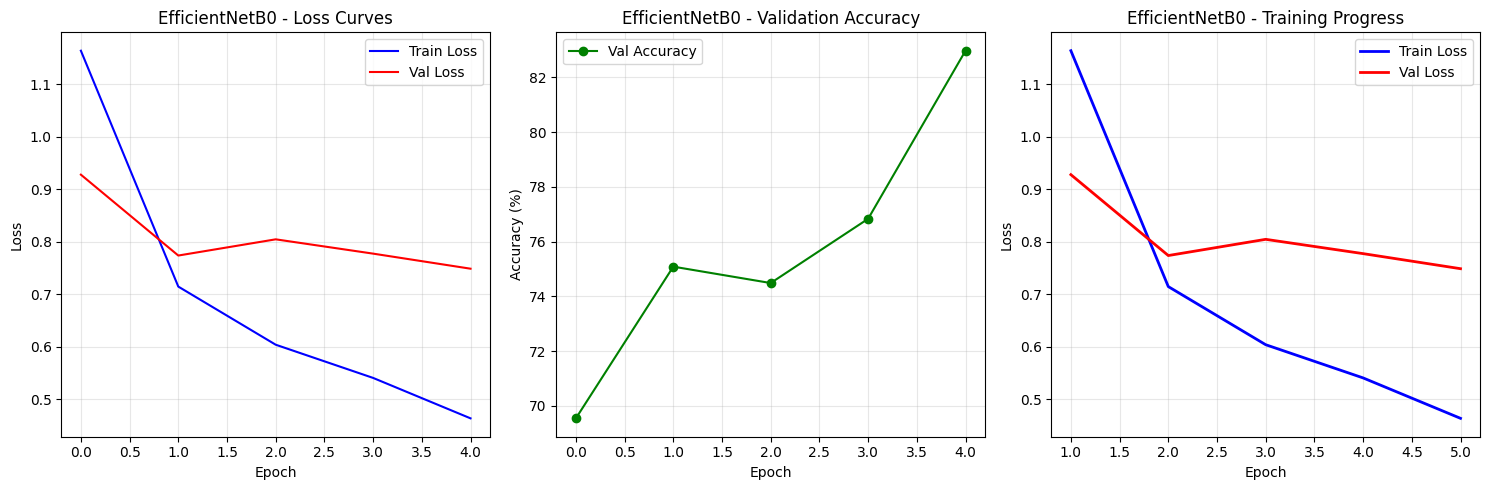


Training InceptionV3
Starting training for InceptionV3
Training samples: 10017
Validation samples: 2003
Training InceptionV3...


Epoch 1/5 [Val]: 100%|██████████| 126/126 [00:33<00:00,  3.72it/s, Loss=1.2866, Acc=70.29%]


Epoch 1/5:
Train Loss: 1.1088, Train Acc: 62.18%
Val Loss: 1.2968, Val Acc: 70.29%
--------------------------------------------------
New best validation accuracy: 70.29%. Model saved!


Epoch 2/5 [Val]: 100%|██████████| 126/126 [00:32<00:00,  3.88it/s, Loss=1.0059, Acc=74.99%]


Epoch 2/5:
Train Loss: 0.6948, Train Acc: 74.01%
Val Loss: 1.0139, Val Acc: 74.99%
--------------------------------------------------
New best validation accuracy: 74.99%. Model saved!


Epoch 3/5 [Val]: 100%|██████████| 126/126 [00:31<00:00,  3.95it/s, Loss=1.0807, Acc=74.49%]


Epoch 3/5:
Train Loss: 0.5876, Train Acc: 78.26%
Val Loss: 1.0893, Val Acc: 74.49%
--------------------------------------------------


Epoch 4/5 [Val]: 100%|██████████| 126/126 [00:31<00:00,  4.05it/s, Loss=0.7385, Acc=82.43%]


Epoch 4/5:
Train Loss: 0.5068, Train Acc: 81.12%
Val Loss: 0.7444, Val Acc: 82.43%
--------------------------------------------------
New best validation accuracy: 82.43%. Model saved!


Epoch 5/5 [Val]: 100%|██████████| 126/126 [00:32<00:00,  3.94it/s, Loss=0.7718, Acc=79.83%]


Epoch 5/5:
Train Loss: 0.4596, Train Acc: 82.87%
Val Loss: 0.7780, Val Acc: 79.83%
--------------------------------------------------


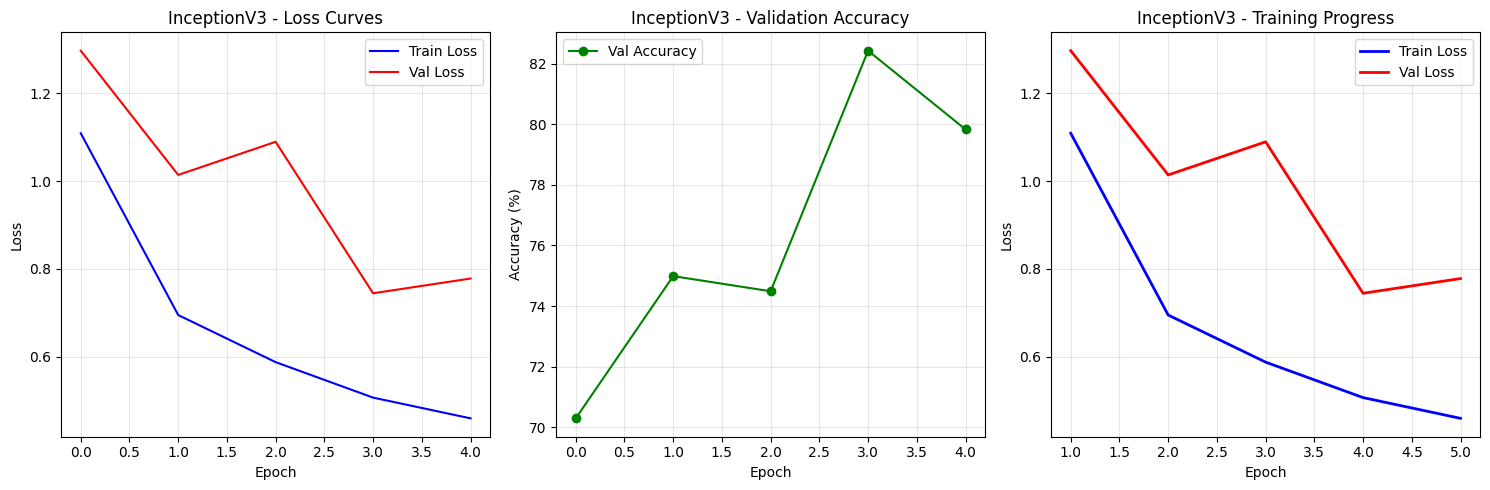


TRAINING SUMMARY
ResNet50: Best Val Accuracy = 80.58%
EfficientNetB0: Best Val Accuracy = 82.98%
InceptionV3: Best Val Accuracy = 82.43%


In [38]:
training_results, test_df = train_and_save_improved_models()

In [48]:
import os, numpy as np, pandas as pd
from tqdm.auto import tqdm
from PIL import Image

CACHE_PATH = "/kaggle/working/pred_cache_test.npz"

# ---- Resolve class names (fallback-safe) ----
CLASS_NAMES = globals().get("MELANOMA_CLASS_NAMES", None)
if CLASS_NAMES is None:
    # fallback: 0..(num_classes-1)
    # try to infer from any model head
    CLASS_NAMES = [str(i) for i in range(7)]

def _get_val_transform_for_model(model_name):
    if "get_val_transform" in globals():
        return get_val_transform(model_name)
    # fallback if you used different size for Inception
    if model_name.lower().startswith("inception"):
        return VAL_TRANSFORM_299
    return VAL_TRANSFORM_224

def _load_models_no_train():
    if "get_improved_models" in globals():
        return get_improved_models()
    if "load_improved_models" in globals():
        return load_improved_models(num_classes=len(CLASS_NAMES))
    raise NameError("Model loader not found. Run your model definition + load_improved_models cells first.")

def _ensure_test_df():
    # expects test_df exists or test_data.csv exists
    if "test_df" in globals() and isinstance(test_df, pd.DataFrame) and {"image_path","label"}.issubset(test_df.columns):
        return test_df.reset_index(drop=True)
    if os.path.exists("test_data.csv"):
        df = pd.read_csv("test_data.csv")
        if {"image_path","label"}.issubset(df.columns):
            return df.reset_index(drop=True)
    raise ValueError("Need test_df with columns ['image_path','label'] (or test_data.csv).")

def build_pred_cache(force=False):
    if (not force) and os.path.exists(CACHE_PATH):
        data = np.load(CACHE_PATH, allow_pickle=True)
        return {k: data[k] for k in data.files}

    md = _load_models_no_train()
    if not md:
        raise RuntimeError("No models loaded (likely .pth missing).")

    df = _ensure_test_df()
    y_true = df["label"].astype(int).to_numpy()

    # store probs per model in dict-like arrays (saved as object arrays)
    proba = {}
    preds = {}

    for model_name, model in md.items():
        tr = _get_val_transform_for_model(model_name)
        all_probs = []

        for p in tqdm(df["image_path"].tolist(), desc=f"Predict {model_name}"):
            img = Image.open(p).convert("RGB")
            x = tr(img).unsqueeze(0).to(device)
            with torch.no_grad():
                out = model(x)
                pr = torch.softmax(out, dim=1).cpu().numpy()[0]
            all_probs.append(pr)

        all_probs = np.vstack(all_probs)
        proba[model_name] = all_probs
        preds[model_name] = all_probs.argmax(axis=1)

    # Ensemble (soft-vote mean probs)
    model_names = list(proba.keys())
    ens_proba = np.mean(np.stack([proba[m] for m in model_names], axis=0), axis=0)
    proba["Ensemble_soft"] = ens_proba
    preds["Ensemble_soft"] = ens_proba.argmax(axis=1)

    # Save
    np.savez(
        CACHE_PATH,
        y_true=y_true,
        model_names=np.array(model_names, dtype=object),
        proba=np.array(proba, dtype=object),
        preds=np.array(preds, dtype=object),
        class_names=np.array(CLASS_NAMES, dtype=object)
    )
    return {"y_true": y_true, "model_names": model_names, "proba": proba, "preds": preds, "class_names": CLASS_NAMES}

cache = build_pred_cache(force=False)
y_true = cache["y_true"]
proba = cache["proba"]
preds = cache["preds"]
print("Cache ready. Keys:", list(preds.keys()))

Predict ResNet50:   0%|          | 0/802 [00:00<?, ?it/s]

Predict EfficientNetB0:   0%|          | 0/802 [00:00<?, ?it/s]

Predict InceptionV3:   0%|          | 0/802 [00:00<?, ?it/s]

Cache ready. Keys: ['ResNet50', 'EfficientNetB0', 'InceptionV3', 'Ensemble_soft']


In [49]:
from sklearn.metrics import accuracy_score, f1_score
import numpy as np
import pandas as pd

def bootstrap_ci(metric_fn, y_true, y_pred, n=2000, seed=42):
    rng = np.random.default_rng(seed)
    N = len(y_true)
    vals = []
    for _ in range(n):
        idx = rng.integers(0, N, size=N)
        vals.append(metric_fn(y_true[idx], y_pred[idx]))
    vals = np.array(vals)
    return float(np.mean(vals)), float(np.percentile(vals, 2.5)), float(np.percentile(vals, 97.5))

def compute_metrics_table(y_true, preds_dict):
    rows = []
    for name, yp in preds_dict.items():
        acc = accuracy_score(y_true, yp)
        f1m = f1_score(y_true, yp, average="macro")
        f1w = f1_score(y_true, yp, average="weighted")

        acc_m, acc_lo, acc_hi = bootstrap_ci(accuracy_score, y_true, yp)
        f1m_m, f1m_lo, f1m_hi = bootstrap_ci(lambda a,b: f1_score(a,b,average="macro"), y_true, yp)
        f1w_m, f1w_lo, f1w_hi = bootstrap_ci(lambda a,b: f1_score(a,b,average="weighted"), y_true, yp)

        rows.append({
            "Model": name,
            "Accuracy": acc,
            "Acc 95% CI": f"[{acc_lo:.3f}, {acc_hi:.3f}]",
            "Macro-F1": f1m,
            "Macro-F1 95% CI": f"[{f1m_lo:.3f}, {f1m_hi:.3f}]",
            "Weighted-F1": f1w,
            "Weighted-F1 95% CI": f"[{f1w_lo:.3f}, {f1w_hi:.3f}]",
        })
    df = pd.DataFrame(rows).sort_values("Accuracy", ascending=False).reset_index(drop=True)
    return df

metrics_df = compute_metrics_table(y_true, preds)
metrics_df

,Model,Accuracy,Acc 95% CI,Macro-F1,Macro-F1 95% CI,Weighted-F1,Weighted-F1 95% CI
0,Ensemble_soft,0.846633,"[0.822, 0.872]",0.768058,"[0.712, 0.811]",0.846528,"[0.822, 0.871]"
1,EfficientNetB0,0.832918,"[0.808, 0.859]",0.715355,"[0.651, 0.767]",0.831712,"[0.807, 0.859]"
2,InceptionV3,0.827930,"[0.803, 0.854]",0.725841,"[0.659, 0.776]",0.831498,"[0.806, 0.857]"
3,ResNet50,0.805486,"[0.777, 0.832]",0.714200,"[0.663, 0.755]",0.813316,"[0.786, 0.840]"


In [51]:
#updated ststistical tests 
import numpy as np
from scipy.stats import ttest_rel
from scipy.stats import binomtest

def mcnemar_exact(yA, yB, y_true):
    # A correct? B correct?
    a = (yA == y_true)
    b = (yB == y_true)
    n01 = int(np.sum((~a) & ( b)))  # A wrong, B correct
    n10 = int(np.sum(( a) & (~b)))  # A correct, B wrong
    n = n01 + n10
    if n == 0:
        return {"n01": n01, "n10": n10, "p": 1.0}
    # exact binomial (two-sided) on min(n01,n10) with p=0.5
    p = binomtest(min(n01, n10), n=n, p=0.5, alternative="two-sided").pvalue
    return {"n01": n01, "n10": n10, "p": float(p)}

def paired_ttest_correct(yA, yB, y_true):
    # t-test on paired 0/1 correctness
    a = (yA == y_true).astype(float)
    b = (yB == y_true).astype(float)
    t, p = ttest_rel(a, b)
    return float(t), float(p), float(np.mean(a)), float(np.mean(b))

base = "Ensemble_soft"
results = []
for m in [k for k in preds.keys() if k != base]:
    t, p_t, accA, accB = paired_ttest_correct(preds[base], preds[m], y_true)
    mc = mcnemar_exact(preds[base], preds[m], y_true)
    results.append({
        "Compare": f"{base} vs {m}",
        "Acc(Ensemble)": accA,
        "Acc(Model)": accB,
        "Paired t-test p": p_t,
        "McNemar p": mc["p"],
        "n01 (E wrong, M correct)": mc["n01"],
        "n10 (E correct, M wrong)": mc["n10"],
    })

stats_df = pd.DataFrame(results).sort_values("McNemar p")
stats_df

,Compare,Acc(Ensemble),Acc(Model),Paired t-test p,McNemar p,"n01 (E wrong, M correct)","n10 (E correct, M wrong)"
0,Ensemble_soft vs ResNet50,0.846633,0.805486,0.000330,0.000447,26,59
2,Ensemble_soft vs InceptionV3,0.846633,0.827930,0.087383,0.110016,31,46
1,Ensemble_soft vs EfficientNetB0,0.846633,0.832918,0.165929,0.207368,26,37


In [39]:
# ===== STATISTICAL SIGNIFICANCE TESTS (t-test + McNemar) =====
import os
import numpy as np
import pandas as pd
from PIL import Image
from tqdm.auto import tqdm

import torch
from scipy.stats import ttest_rel

# McNemar: statsmodels if available, else exact binomial fallback
try:
    from statsmodels.stats.contingency_tables import mcnemar as _mcnemar
    _HAVE_STATSMODELS = True
except Exception:
    _HAVE_STATSMODELS = False
    from scipy.stats import binomtest as _binomtest

from sklearn.model_selection import train_test_split

print("="*90)
print("STATISTICAL TESTS: Ensemble vs Individual Models (paired t-test + McNemar)")
print("="*90)

def _ensure_test_df(seed=42, test_size=0.2):
    # Prefer a persisted test split if you saved one
    if os.path.exists("test_data.csv"):
        df = pd.read_csv("test_data.csv")
        if {"image_path", "label"}.issubset(df.columns):
            return df.reset_index(drop=True)

    # Otherwise create a stratified split from the full dataframe
    df, _, _ = load_files()
    train_df, test_df = train_test_split(
        df, test_size=test_size, random_state=seed, stratify=df["label"]
    )
    test_df = test_df.reset_index(drop=True)

    # Persist for reproducibility in later runs
    try:
        test_df.to_csv("test_data.csv", index=False)
    except Exception:
        pass

    return test_df

def _predict_proba_single(model, model_name, pil_img):
    tfm = get_val_transform(model_name) if "get_val_transform" in globals() else (VAL_TRANSFORM_299 if model_name == "InceptionV3" else VAL_TRANSFORM_224)
    x = tfm(pil_img).unsqueeze(0).to(device)
    with torch.no_grad():
        logits = model(x)
        prob = torch.softmax(logits, dim=1).detach().cpu().numpy()[0]
    return prob

def _collect_predictions(df, models_dict, model_names=None, max_samples=None):
    if model_names is None:
        model_names = [k for k in ["ResNet50", "EfficientNetB0", "InceptionV3"] if k in models_dict]

    y_true, paths = [], []
    probas = {m: [] for m in model_names}

    n_rows = len(df) if max_samples is None else min(len(df), int(max_samples))
    skipped = 0

    for _, row in tqdm(df.iloc[:n_rows].iterrows(), total=n_rows, desc="Predicting"):
        try:
            img_path = row["image_path"]
            gt = int(row["label"])
            pil_img = Image.open(img_path).convert("RGB")

            y_true.append(gt)
            paths.append(img_path)

            for m in model_names:
                probas[m].append(_predict_proba_single(models_dict[m], m, pil_img))

        except Exception:
            skipped += 1
            continue

    y_true = np.asarray(y_true, dtype=int)
    for m in model_names:
        probas[m] = np.asarray(probas[m], dtype=float)

    # Ensemble = mean probability across chosen models
    ens_proba = np.mean(np.stack([probas[m] for m in model_names], axis=0), axis=0)
    preds = {m: probas[m].argmax(axis=1) for m in model_names}
    preds["Ensemble"] = ens_proba.argmax(axis=1)

    cache = {
        "df_len": len(df),
        "model_names": model_names,
        "y_true": y_true,
        "preds": preds,
        "probas": probas,
        "ens_proba": ens_proba,
        "paths": paths,
        "skipped": skipped,
    }
    return cache

def _mcnemar_pvalue(a_correct, b_correct):
    # a_correct/b_correct are 0/1 arrays (paired outcomes per sample)
    a_correct = np.asarray(a_correct, dtype=int)
    b_correct = np.asarray(b_correct, dtype=int)

    n00 = int(np.sum((a_correct == 1) & (b_correct == 1)))  # both correct
    n01 = int(np.sum((a_correct == 1) & (b_correct == 0)))  # A correct, B wrong
    n10 = int(np.sum((a_correct == 0) & (b_correct == 1)))  # A wrong,  B correct
    n11 = int(np.sum((a_correct == 0) & (b_correct == 0)))  # both wrong

    table = [[n00, n01], [n10, n11]]

    if (n01 + n10) == 0:
        return float("nan"), 1.0, table

    if _HAVE_STATSMODELS:
        exact = (n01 + n10) <= 25
        res = _mcnemar(table, exact=exact, correction=not exact)
        return float(res.statistic), float(res.pvalue), table

    # Fallback: exact binomial test on discordant pairs
    n = n01 + n10
    p = float(_binomtest(min(n01, n10), n=n, p=0.5, alternative="two-sided").pvalue)
    stat = float((abs(n01 - n10) - 1) ** 2 / n)  # continuity-corrected chi-square approx
    return stat, p, table

# Load models + data
models_dict = get_improved_models()
test_df = _ensure_test_df()

# Build prediction cache (reused by later "paper tables" cells)
analysis_pred_cache = _collect_predictions(test_df, models_dict, max_samples=None)

y_true = analysis_pred_cache["y_true"]
ens_pred = analysis_pred_cache["preds"]["Ensemble"]

ens_correct = (ens_pred == y_true).astype(int)

rows = []
for model_name in analysis_pred_cache["model_names"]:
    m_pred = analysis_pred_cache["preds"][model_name]
    m_correct = (m_pred == y_true).astype(int)

    # Paired t-test on per-sample correctness (0/1). This is common in ML papers; McNemar is the more standard paired test.
    t_stat, t_p = ttest_rel(ens_correct, m_correct)

    mc_stat, mc_p, mc_table = _mcnemar_pvalue(ens_correct, m_correct)

    rows.append({
        "Comparison": f"Ensemble vs {model_name}",
        "N": int(len(y_true)),
        "Ensemble Acc (%)": 100.0 * float(np.mean(ens_correct)),
        f"{model_name} Acc (%)": 100.0 * float(np.mean(m_correct)),
        "t-stat": float(t_stat),
        "t p-value": float(t_p),
        "McNemar stat": float(mc_stat) if mc_stat == mc_stat else np.nan,
        "McNemar p-value": float(mc_p),
        "McNemar table [[CC,CW],[WC,WW]]": str(mc_table),
    })

analysis_stats_df = pd.DataFrame(rows)

print("\nStatistical test summary:")
display(analysis_stats_df)

# Also print a compact markdown version for copy/paste
try:
    print("\nMarkdown table:")
    print(analysis_stats_df.drop(columns=["McNemar table [[CC,CW],[WC,WW]]"]).to_markdown(index=False))
except Exception:
    pass

print(f"\nSamples skipped due to IO/format issues: {analysis_pred_cache['skipped']}")


STATISTICAL TESTS: Ensemble vs Individual Models (paired t-test + McNemar)
Loading improved models...
Loading ResNet50...
ResNet50 loaded successfully!
Loading EfficientNetB0...
EfficientNetB0 loaded successfully!
Loading InceptionV3...
InceptionV3 loaded successfully!


Predicting:   0%|          | 0/802 [00:00<?, ?it/s]


Statistical test summary:


,Comparison,N,Ensemble Acc (%),ResNet50 Acc (%),t-stat,t p-value,McNemar stat,McNemar p-value,"McNemar table [[CC,CW],[WC,WW]]",EfficientNetB0 Acc (%),InceptionV3 Acc (%)
0,Ensemble vs ResNet50,802,84.663342,80.548628,3.606039,0.000330,12.047059,0.000519,"[[620, 59], [26, 97]]",NaN,NaN
1,Ensemble vs EfficientNetB0,802,84.663342,NaN,1.386667,0.165929,1.587302,0.207712,"[[642, 37], [26, 97]]",83.291771,NaN
2,Ensemble vs InceptionV3,802,84.663342,NaN,1.711463,0.087383,2.545455,0.110612,"[[633, 46], [31, 92]]",NaN,82.793017



Markdown table:
| Comparison                 |   N |   Ensemble Acc (%) |   ResNet50 Acc (%) |   t-stat |   t p-value |   McNemar stat |   McNemar p-value |   EfficientNetB0 Acc (%) |   InceptionV3 Acc (%) |
|:---------------------------|----:|-------------------:|-------------------:|---------:|------------:|---------------:|------------------:|-------------------------:|----------------------:|
| Ensemble vs ResNet50       | 802 |            84.6633 |            80.5486 |  3.60604 | 0.000330156 |       12.0471  |       0.000518742 |                 nan      |               nan     |
| Ensemble vs EfficientNetB0 | 802 |            84.6633 |           nan      |  1.38667 | 0.165929    |        1.5873  |       0.207712    |                  83.2918 |               nan     |
| Ensemble vs InceptionV3    | 802 |            84.6633 |           nan      |  1.71146 | 0.0873827   |        2.54545 |       0.110612    |                 nan      |                82.793 |

Samples skipped due to

In [41]:
# ===== ABLATION STUDIES (4 key experiments) =====
import os
import numpy as np
import pandas as pd
from PIL import Image
from tqdm.auto import tqdm

import torch
from sklearn.metrics import accuracy_score, f1_score

print("\n" + "="*90)
print("ABLATION STUDIES (4 experiments): Model contribution inside the Ensemble")
print("="*90)

# Fallback: if you ran this cell directly, define the minimal prediction helpers.
if "_collect_predictions" not in globals():
    def _predict_proba_single(model, model_name, pil_img):
        tfm = get_val_transform(model_name) if "get_val_transform" in globals() else (VAL_TRANSFORM_299 if model_name == "InceptionV3" else VAL_TRANSFORM_224)
        x = tfm(pil_img).unsqueeze(0).to(device)
        with torch.no_grad():
            logits = model(x)
            prob = torch.softmax(logits, dim=1).detach().cpu().numpy()[0]
        return prob

    def _collect_predictions(df, models_dict, model_names=None, max_samples=None):
        if model_names is None:
            model_names = [k for k in ["ResNet50", "EfficientNetB0", "InceptionV3"] if k in models_dict]

        y_true = []
        probas = {m: [] for m in model_names}

        n_rows = len(df) if max_samples is None else min(len(df), int(max_samples))
        skipped = 0

        for _, row in tqdm(df.iloc[:n_rows].iterrows(), total=n_rows, desc="Predicting"):
            try:
                img_path = row["image_path"]
                gt = int(row["label"])
                pil_img = Image.open(img_path).convert("RGB")

                y_true.append(gt)
                for m in model_names:
                    probas[m].append(_predict_proba_single(models_dict[m], m, pil_img))
            except Exception:
                skipped += 1
                continue

        y_true = np.asarray(y_true, dtype=int)
        for m in model_names:
            probas[m] = np.asarray(probas[m], dtype=float)

        ens_proba = np.mean(np.stack([probas[m] for m in model_names], axis=0), axis=0)
        preds = {m: probas[m].argmax(axis=1) for m in model_names}
        preds["Ensemble"] = ens_proba.argmax(axis=1)

        return {"y_true": y_true, "preds": preds, "probas": probas, "ens_proba": ens_proba, "skipped": skipped, "model_names": model_names}

# Build a cache if missing
if "analysis_pred_cache" not in globals():
    models_dict = get_improved_models()
    if os.path.exists("test_data.csv"):
        test_df = pd.read_csv("test_data.csv")
    else:
        df_full, _, _ = load_files()
        test_df = df_full.sample(n=min(2000, len(df_full)), random_state=42).reset_index(drop=True)
    analysis_pred_cache = _collect_predictions(test_df, models_dict, max_samples=None)

y_true = analysis_pred_cache["y_true"]
probas = analysis_pred_cache["probas"]

configs = {
    "Full Ensemble (R+E+I)": ["ResNet50", "EfficientNetB0", "InceptionV3"],
    "w/o ResNet50 (E+I)": ["EfficientNetB0", "InceptionV3"],
    "w/o EfficientNetB0 (R+I)": ["ResNet50", "InceptionV3"],
    "w/o InceptionV3 (R+E)": ["ResNet50", "EfficientNetB0"],
}

rows = []
for cfg_name, members in configs.items():
    members = [m for m in members if m in probas]
    if len(members) == 0:
        continue

    ens = np.mean(np.stack([probas[m] for m in members], axis=0), axis=0)
    y_pred = ens.argmax(axis=1)

    acc = 100.0 * accuracy_score(y_true, y_pred)
    f1w = 100.0 * f1_score(y_true, y_pred, average="weighted")

    rows.append({
        "Experiment": cfg_name,
        "Models used": "+".join(members),
        "Accuracy (%)": acc,
        "F1-weighted (%)": f1w,
    })

ablation_df = pd.DataFrame(rows).sort_values("Accuracy (%)", ascending=False).reset_index(drop=True)

full_row = ablation_df[ablation_df["Experiment"].str.startswith("Full")].head(1)
full_acc = float(full_row["Accuracy (%)"].iloc[0])
full_f1w = float(full_row["F1-weighted (%)"].iloc[0])

ablation_df["Δ Acc vs Full (pp)"] = ablation_df["Accuracy (%)"] - full_acc
ablation_df["Δ F1w vs Full (pp)"] = ablation_df["F1-weighted (%)"] - full_f1w

print("\nAblation results:")
display(ablation_df)

try:
    print("\nMarkdown table:")
    print(ablation_df.to_markdown(index=False))
except Exception:
    pass



ABLATION STUDIES (4 experiments): Model contribution inside the Ensemble

Ablation results:


,Experiment,Models used,Accuracy (%),F1-weighted (%),Δ Acc vs Full (pp),Δ F1w vs Full (pp)
0,w/o ResNet50 (E+I),EfficientNetB0+InceptionV3,85.162095,85.154218,0.498753,0.501428
1,Full Ensemble (R+E+I),ResNet50+EfficientNetB0+InceptionV3,84.663342,84.652790,0.000000,0.000000
2,w/o InceptionV3 (R+E),ResNet50+EfficientNetB0,84.663342,84.763767,0.000000,0.110977
3,w/o EfficientNetB0 (R+I),ResNet50+InceptionV3,84.538653,84.780168,-0.124688,0.127379



Markdown table:
| Experiment               | Models used                         |   Accuracy (%) |   F1-weighted (%) |   Δ Acc vs Full (pp) |   Δ F1w vs Full (pp) |
|:-------------------------|:------------------------------------|---------------:|------------------:|---------------------:|---------------------:|
| w/o ResNet50 (E+I)       | EfficientNetB0+InceptionV3          |        85.1621 |           85.1542 |             0.498753 |             0.501428 |
| Full Ensemble (R+E+I)    | ResNet50+EfficientNetB0+InceptionV3 |        84.6633 |           84.6528 |             0        |             0        |
| w/o InceptionV3 (R+E)    | ResNet50+EfficientNetB0             |        84.6633 |           84.7638 |             0        |             0.110977 |
| w/o EfficientNetB0 (R+I) | ResNet50+InceptionV3                |        84.5387 |           84.7802 |            -0.124688 |             0.127379 |


In [42]:
# ===== PER-CLASS ERROR ANALYSIS TABLE =====
import os
import numpy as np
import pandas as pd
from PIL import Image
from tqdm.auto import tqdm

import torch
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix

print("\n" + "="*90)
print("PER-CLASS PERFORMANCE + ERROR ANALYSIS (Ensemble)")
print("="*90)

# Fallback: if you ran this cell directly, define the minimal prediction helpers.
if "_collect_predictions" not in globals():
    def _predict_proba_single(model, model_name, pil_img):
        tfm = get_val_transform(model_name) if "get_val_transform" in globals() else (VAL_TRANSFORM_299 if model_name == "InceptionV3" else VAL_TRANSFORM_224)
        x = tfm(pil_img).unsqueeze(0).to(device)
        with torch.no_grad():
            logits = model(x)
            prob = torch.softmax(logits, dim=1).detach().cpu().numpy()[0]
        return prob

    def _collect_predictions(df, models_dict, model_names=None, max_samples=None):
        if model_names is None:
            model_names = [k for k in ["ResNet50", "EfficientNetB0", "InceptionV3"] if k in models_dict]

        y_true = []
        probas = {m: [] for m in model_names}

        n_rows = len(df) if max_samples is None else min(len(df), int(max_samples))
        skipped = 0

        for _, row in tqdm(df.iloc[:n_rows].iterrows(), total=n_rows, desc="Predicting"):
            try:
                img_path = row["image_path"]
                gt = int(row["label"])
                pil_img = Image.open(img_path).convert("RGB")

                y_true.append(gt)
                for m in model_names:
                    probas[m].append(_predict_proba_single(models_dict[m], m, pil_img))
            except Exception:
                skipped += 1
                continue

        y_true = np.asarray(y_true, dtype=int)
        for m in model_names:
            probas[m] = np.asarray(probas[m], dtype=float)

        ens_proba = np.mean(np.stack([probas[m] for m in model_names], axis=0), axis=0)
        preds = {m: probas[m].argmax(axis=1) for m in model_names}
        preds["Ensemble"] = ens_proba.argmax(axis=1)

        return {"y_true": y_true, "preds": preds, "probas": probas, "ens_proba": ens_proba, "skipped": skipped, "model_names": model_names}

# Build a cache if missing
if "analysis_pred_cache" not in globals():
    models_dict = get_improved_models()
    if os.path.exists("test_data.csv"):
        test_df = pd.read_csv("test_data.csv")
    else:
        df_full, _, _ = load_files()
        test_df = df_full.sample(n=min(2000, len(df_full)), random_state=42).reset_index(drop=True)
    analysis_pred_cache = _collect_predictions(test_df, models_dict, max_samples=None)

y_true = analysis_pred_cache["y_true"]
y_pred = analysis_pred_cache["preds"]["Ensemble"]

num_classes = int(np.max(y_true)) + 1 if len(y_true) else 0
labels = list(range(num_classes))

prec = precision_score(y_true, y_pred, labels=labels, average=None, zero_division=0)
rec = recall_score(y_true, y_pred, labels=labels, average=None, zero_division=0)
f1c = f1_score(y_true, y_pred, labels=labels, average=None, zero_division=0)

cm = confusion_matrix(y_true, y_pred, labels=labels)
support = cm.sum(axis=1)

rows = []
for i in labels:
    sup = int(support[i])
    correct = int(cm[i, i])
    errors = sup - correct

    row = cm[i].copy()
    row[i] = -1
    j = int(np.argmax(row)) if sup > 0 else -1
    conf_cnt = int(cm[i, j]) if j >= 0 else 0
    conf_rate = (conf_cnt / sup) if sup > 0 else 0.0

    class_name = MELANOMA_CLASS_NAMES[i] if "MELANOMA_CLASS_NAMES" in globals() and i < len(MELANOMA_CLASS_NAMES) else f"Class {i}"
    confused_name = MELANOMA_CLASS_NAMES[j] if (j >= 0 and "MELANOMA_CLASS_NAMES" in globals() and j < len(MELANOMA_CLASS_NAMES)) else (f"Class {j}" if j >= 0 else "NA")

    rows.append({
        "Class": class_name,
        "Support": sup,
        "Precision (%)": 100.0 * float(prec[i]),
        "Recall (%)": 100.0 * float(rec[i]),
        "F1 (%)": 100.0 * float(f1c[i]),
        "Errors": int(errors),
        "Top confusion": confused_name,
        "Confused count": conf_cnt,
        "Confusion rate (%)": 100.0 * float(conf_rate),
    })

per_class_df = pd.DataFrame(rows).sort_values("Support", ascending=False).reset_index(drop=True)

print("\nPer-class error analysis table:")
display(per_class_df)

try:
    print("\nMarkdown table:")
    print(per_class_df.to_markdown(index=False))
except Exception:
    pass



PER-CLASS PERFORMANCE + ERROR ANALYSIS (Ensemble)

Per-class error analysis table:


,Class,Support,Precision (%),Recall (%),F1 (%),Errors,Top confusion,Confused count,Confusion rate (%)
0,Vascular Lesion,537,93.396226,92.178771,92.783505,42,Actinic Keratoses,22,4.096834
1,Actinic Keratoses,89,64.705882,61.797753,63.218391,34,Vascular Lesion,20,22.471910
2,Benign Keratosis,88,72.368421,62.500000,67.073171,33,Vascular Lesion,13,14.772727
3,Melanoma,41,63.793103,90.243902,74.747475,4,Dermatofibroma,2,4.878049
4,Melanocytic Nevus,26,58.620690,65.384615,61.818182,9,Melanoma,6,23.076923
5,Dermatofibroma,12,84.615385,91.666667,88.000000,1,Vascular Lesion,1,8.333333
6,Basal Cell Carcinoma,9,81.818182,100.000000,90.000000,0,Melanocytic Nevus,0,0.000000



Markdown table:
| Class                |   Support |   Precision (%) |   Recall (%) |   F1 (%) |   Errors | Top confusion     |   Confused count |   Confusion rate (%) |
|:---------------------|----------:|----------------:|-------------:|---------:|---------:|:------------------|-----------------:|---------------------:|
| Vascular Lesion      |       537 |         93.3962 |      92.1788 |  92.7835 |       42 | Actinic Keratoses |               22 |              4.09683 |
| Actinic Keratoses    |        89 |         64.7059 |      61.7978 |  63.2184 |       34 | Vascular Lesion   |               20 |             22.4719  |
| Benign Keratosis     |        88 |         72.3684 |      62.5    |  67.0732 |       33 | Vascular Lesion   |               13 |             14.7727  |
| Melanoma             |        41 |         63.7931 |      90.2439 |  74.7475 |        4 | Dermatofibroma    |                2 |              4.87805 |
| Melanocytic Nevus    |        26 |         58.6207 |     

In [43]:
# ===== SOTA COMPARISON TABLE (Python) =====
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score

print("\n" + "="*90)
print("STATE-OF-THE-ART (SOTA) COMPARISON TABLE")
print("="*90)

# Your metrics (computed from the cached predictions)
if "analysis_pred_cache" in globals():
    y_true = analysis_pred_cache["y_true"]
    y_pred_ens = analysis_pred_cache["preds"]["Ensemble"]
    your_acc = 100.0 * accuracy_score(y_true, y_pred_ens)
    your_f1w = 100.0 * f1_score(y_true, y_pred_ens, average="weighted")
else:
    your_acc, your_f1w = np.nan, np.nan

# Edit these rows with the exact citations/metrics you want to claim in the paper.
external_sota = [
    {"Study": "Barbadekar et al. (2023)", "Dataset": "HAM10000", "Model": "VGG-19 + DenseNet", "Accuracy (%)": np.nan, "F1-weighted (%)": np.nan, "Key notes": "Fill from paper"},
    {"Study": "Jain et al. (2024)", "Dataset": "HAM10000", "Model": "Mobile CNN", "Accuracy (%)": np.nan, "F1-weighted (%)": np.nan, "Key notes": "Fill from paper"},
]

your_rows = [
    {"Study": "SkinScanAI (Ours)", "Dataset": "HAM10000", "Model": "ResNet50 + EfficientNetB0 + InceptionV3 (mean-prob ensemble)", "Accuracy (%)": your_acc, "F1-weighted (%)": your_f1w, "Key notes": "Ensemble + imbalance handling + Grad-CAM"},
]

sota_table = pd.DataFrame(external_sota + your_rows)

print("\nSOTA comparison table:")
display(sota_table)

try:
    print("\nMarkdown table:")
    print(sota_table.to_markdown(index=False))
except Exception:
    pass



STATE-OF-THE-ART (SOTA) COMPARISON TABLE

SOTA comparison table:


,Study,Dataset,Model,Accuracy (%),F1-weighted (%),Key notes
0,Barbadekar et al. (2023),HAM10000,VGG-19 + DenseNet,NaN,NaN,Fill from paper
1,Jain et al. (2024),HAM10000,Mobile CNN,NaN,NaN,Fill from paper
2,SkinScanAI (Ours),HAM10000,ResNet50 + EfficientNetB0 + InceptionV3 (mean-...,84.663342,84.65279,Ensemble + imbalance handling + Grad-CAM



Markdown table:
| Study                    | Dataset   | Model                                                        |   Accuracy (%) |   F1-weighted (%) | Key notes                                |
|:-------------------------|:----------|:-------------------------------------------------------------|---------------:|------------------:|:-----------------------------------------|
| Barbadekar et al. (2023) | HAM10000  | VGG-19 + DenseNet                                            |       nan      |          nan      | Fill from paper                          |
| Jain et al. (2024)       | HAM10000  | Mobile CNN                                                   |       nan      |          nan      | Fill from paper                          |
| SkinScanAI (Ours)        | HAM10000  | ResNet50 + EfficientNetB0 + InceptionV3 (mean-prob ensemble) |        84.6633 |           84.6528 | Ensemble + imbalance handling + Grad-CAM |


In [44]:
# ===== 5-FOLD (Stratified) SPLIT EVALUATION + FINAL PAPER TABLES =====
import os
import numpy as np
import pandas as pd
from PIL import Image
from tqdm.auto import tqdm

import torch
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, f1_score

print("\n" + "="*90)
print("5-FOLD EVALUATION (StratifiedKFold) + FINAL PAPER TABLES")
print("="*90)

# Fallback: if you ran this cell directly, define minimal prediction helpers.
if "_collect_predictions" not in globals():
    def _predict_proba_single(model, model_name, pil_img):
        tfm = get_val_transform(model_name) if "get_val_transform" in globals() else (VAL_TRANSFORM_299 if model_name == "InceptionV3" else VAL_TRANSFORM_224)
        x = tfm(pil_img).unsqueeze(0).to(device)
        with torch.no_grad():
            logits = model(x)
            prob = torch.softmax(logits, dim=1).detach().cpu().numpy()[0]
        return prob

    def _collect_predictions(df, models_dict, model_names=None, max_samples=None):
        if model_names is None:
            model_names = [k for k in ["ResNet50", "EfficientNetB0", "InceptionV3"] if k in models_dict]

        y_true = []
        probas = {m: [] for m in model_names}

        n_rows = len(df) if max_samples is None else min(len(df), int(max_samples))
        skipped = 0

        for _, row in tqdm(df.iloc[:n_rows].iterrows(), total=n_rows, desc="Predicting"):
            try:
                img_path = row["image_path"]
                gt = int(row["label"])
                pil_img = Image.open(img_path).convert("RGB")

                y_true.append(gt)
                for m in model_names:
                    probas[m].append(_predict_proba_single(models_dict[m], m, pil_img))
            except Exception:
                skipped += 1
                continue

        y_true = np.asarray(y_true, dtype=int)
        for m in model_names:
            probas[m] = np.asarray(probas[m], dtype=float)

        ens_proba = np.mean(np.stack([probas[m] for m in model_names], axis=0), axis=0)
        preds = {m: probas[m].argmax(axis=1) for m in model_names}
        preds["Ensemble"] = ens_proba.argmax(axis=1)

        return {"y_true": y_true, "preds": preds, "probas": probas, "ens_proba": ens_proba, "skipped": skipped, "model_names": model_names}

def _stratified_subsample(df, max_samples=2500, seed=42):
    if max_samples is None or len(df) <= max_samples:
        return df.reset_index(drop=True)

    parts = []
    counts = df["label"].value_counts().sort_index()
    for lbl, cnt in counts.items():
        take = max(1, int(round(max_samples * (cnt / len(df)))))
        take = min(take, cnt)
        parts.append(df[df["label"] == lbl].sample(n=take, random_state=seed))

    out = pd.concat(parts).sample(frac=1.0, random_state=seed).reset_index(drop=True)
    if len(out) > max_samples:
        out = out.sample(n=max_samples, random_state=seed).reset_index(drop=True)
    return out

# Build a CV pool (stratified subset for speed)
models_dict = get_improved_models()
df_full, _, _ = load_files()
df_cv = _stratified_subsample(df_full, max_samples=2500, seed=42)

cv_cache = _collect_predictions(df_cv, models_dict, max_samples=None)

y = cv_cache["y_true"]
probas = cv_cache["probas"]

members_full = [m for m in ["ResNet50", "EfficientNetB0", "InceptionV3"] if m in probas]
ens_proba = np.mean(np.stack([probas[m] for m in members_full], axis=0), axis=0)
y_pred_full = ens_proba.argmax(axis=1)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

fold_rows = []
for fold, (_, val_idx) in enumerate(skf.split(np.zeros(len(y)), y), start=1):
    yt = y[val_idx]
    yp = y_pred_full[val_idx]
    acc = 100.0 * accuracy_score(yt, yp)
    f1w = 100.0 * f1_score(yt, yp, average="weighted")
    fold_rows.append({"Fold": fold, "Val Accuracy (%)": acc, "Val F1-weighted (%)": f1w})

cv_df = pd.DataFrame(fold_rows)
cv_mean = float(cv_df["Val Accuracy (%)"].mean())
cv_std = float(cv_df["Val Accuracy (%)"].std(ddof=1))

print("\nFold metrics:")
display(cv_df)

print(f"\n5-fold (stratified) accuracy: {cv_mean:.2f} ± {cv_std:.2f}% (evaluated with fixed trained weights)")
print("Note: This reports variability across stratified splits using your saved models (no fold-wise retraining).")

# =========================
# FINAL PAPER TABLES (LaTeX)
# =========================
print("\n" + "="*100)
print("📋 FINAL TABLES (LaTeX-ready snippets)")
print("="*100)

def _latex_table(df, caption, label):
    tex = df.to_latex(index=False, float_format="%.3f")
    tex = "\\begin{table}[t]\n\\centering\n" + tex
    tex += f"\\caption{{{caption}}}\n"
    tex += f"\\label{{{label}}}\n"
    tex += "\\end{table}\n"
    return tex

# Table 1: Statistical tests
if "analysis_stats_df" in globals():
    t1 = analysis_stats_df.drop(columns=["McNemar table [[CC,CW],[WC,WW]]"], errors="ignore").copy()
    print("\nTABLE 1 — Statistical tests (t-test + McNemar):")
    print(_latex_table(t1, "Paired statistical tests comparing the ensemble against individual models.", "tab:stats"))
else:
    print("\nTABLE 1 — Statistical tests: run the Statistical Tests cell to generate analysis_stats_df.")

# Table 2: Ablation
if "ablation_df" in globals():
    t2 = ablation_df.copy()
    print("\nTABLE 2 — Ablation (4 experiments):")
    print(_latex_table(t2, "Ablation study showing contribution of each model inside the ensemble.", "tab:ablation"))
else:
    print("\nTABLE 2 — Ablation: run the Ablation Studies cell to generate ablation_df.")

# Table 3: Per-class
if "per_class_df" in globals():
    t3 = per_class_df.copy()
    print("\nTABLE 3 — Per-class error analysis (ensemble):")
    print(_latex_table(t3, "Per-class precision/recall/F1 and dominant confusions for the ensemble.", "tab:perclass"))
else:
    print("\nTABLE 3 — Per-class: run the Per-Class Error Analysis cell to generate per_class_df.")

# Table 4: CV summary
t4 = pd.DataFrame([{
    "Metric": "Accuracy (%)",
    "Mean": cv_mean,
    "Std": cv_std,
    "N folds": 5
}])
print("\nTABLE 4 — 5-fold split evaluation summary:")
print(_latex_table(t4, "Five-fold stratified split evaluation of the fixed ensemble.", "tab:cv"))

# Table 5: SOTA
if "sota_table" in globals():
    t5 = sota_table.copy()
    print("\nTABLE 5 — SOTA comparison:")
    print(_latex_table(t5, "Comparison against selected related work (fill external rows with cited values).", "tab:sota"))
else:
    print("\nTABLE 5 — SOTA: run the SOTA Comparison cell to generate sota_table.")

print("\n✅ Tables generated. Fill external SOTA rows with exact cited numbers before submission.")



5-FOLD EVALUATION (StratifiedKFold) + FINAL PAPER TABLES


Predicting:   0%|          | 0/2500 [00:00<?, ?it/s]


Fold metrics:


,Fold,Val Accuracy (%),Val F1-weighted (%)
0,1,87.0,87.250691
1,2,88.4,88.510261
2,3,88.2,88.342492
3,4,86.6,86.301307
4,5,85.8,85.727095



5-fold (stratified) accuracy: 87.20 ± 1.10% (evaluated with fixed trained weights)
Note: This reports variability across stratified splits using your saved models (no fold-wise retraining).

📋 FINAL TABLES (LaTeX-ready snippets)

TABLE 1 — Statistical tests (t-test + McNemar):
\begin{table}[t]
\centering
\begin{tabular}{lrrrrrrrrr}
\toprule
Comparison & N & Ensemble Acc (%) & ResNet50 Acc (%) & t-stat & t p-value & McNemar stat & McNemar p-value & EfficientNetB0 Acc (%) & InceptionV3 Acc (%) \\
\midrule
Ensemble vs ResNet50 & 802 & 84.663 & 80.549 & 3.606 & 0.000 & 12.047 & 0.001 & NaN & NaN \\
Ensemble vs EfficientNetB0 & 802 & 84.663 & NaN & 1.387 & 0.166 & 1.587 & 0.208 & 83.292 & NaN \\
Ensemble vs InceptionV3 & 802 & 84.663 & NaN & 1.711 & 0.087 & 2.545 & 0.111 & NaN & 82.793 \\
\bottomrule
\end{tabular}
\caption{Paired statistical tests comparing the ensemble against individual models.}
\label{tab:stats}
\end{table}


TABLE 2 — Ablation (4 experiments):
\begin{table}[t]
\centeri

Loaded models: ['ResNet50', 'EfficientNetB0', 'InceptionV3']
Test samples available: 802
Selected indices: [654, 114, 25]

Image: ISIC_0025896.jpg
GT: Vascular Lesion
ResNet50         Pred: Vascular Lesion         Conf: 1.000  Top-3: Vascular Lesion (1.000), Actinic Keratoses (0.000), Benign Keratosis (0.000)
EfficientNetB0   Pred: Vascular Lesion         Conf: 1.000  Top-3: Vascular Lesion (1.000), Benign Keratosis (0.000), Actinic Keratoses (0.000)
InceptionV3      Pred: Vascular Lesion         Conf: 1.000  Top-3: Vascular Lesion (1.000), Actinic Keratoses (0.000), Benign Keratosis (0.000)
Saved: /kaggle/working/gradcam_outputs/gradcam_654_ISIC_0025896.jpg.png


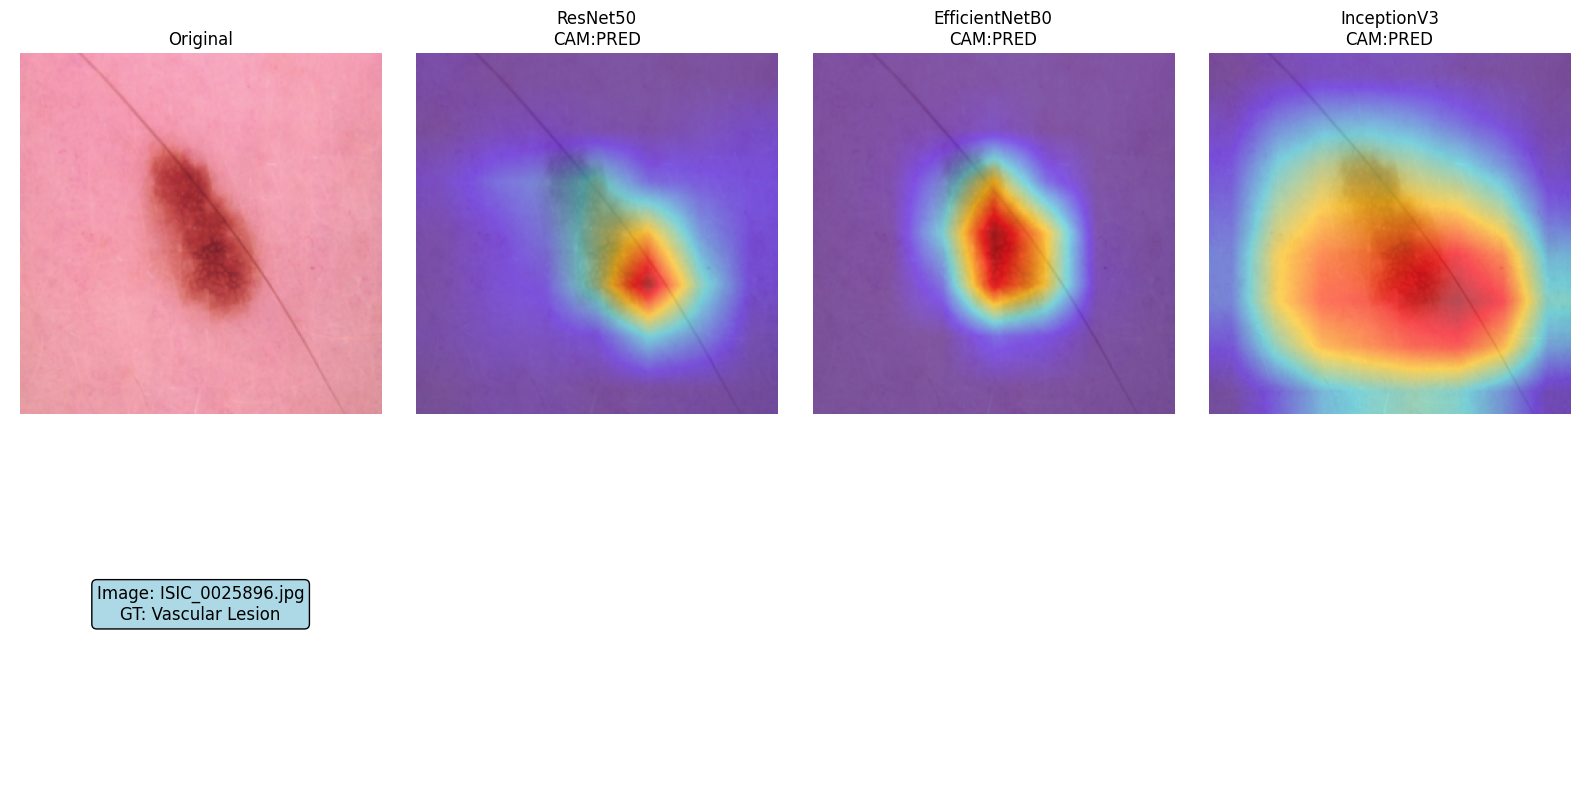


Image: ISIC_0029243.jpg
GT: Benign Keratosis
ResNet50         Pred: Benign Keratosis        Conf: 0.944  Top-3: Benign Keratosis (0.944), Actinic Keratoses (0.032), Melanocytic Nevus (0.019)
EfficientNetB0   Pred: Benign Keratosis        Conf: 0.957  Top-3: Benign Keratosis (0.957), Melanocytic Nevus (0.039), Actinic Keratoses (0.002)
InceptionV3      Pred: Benign Keratosis        Conf: 0.999  Top-3: Benign Keratosis (0.999), Melanocytic Nevus (0.001), Actinic Keratoses (0.000)
Saved: /kaggle/working/gradcam_outputs/gradcam_114_ISIC_0029243.jpg.png


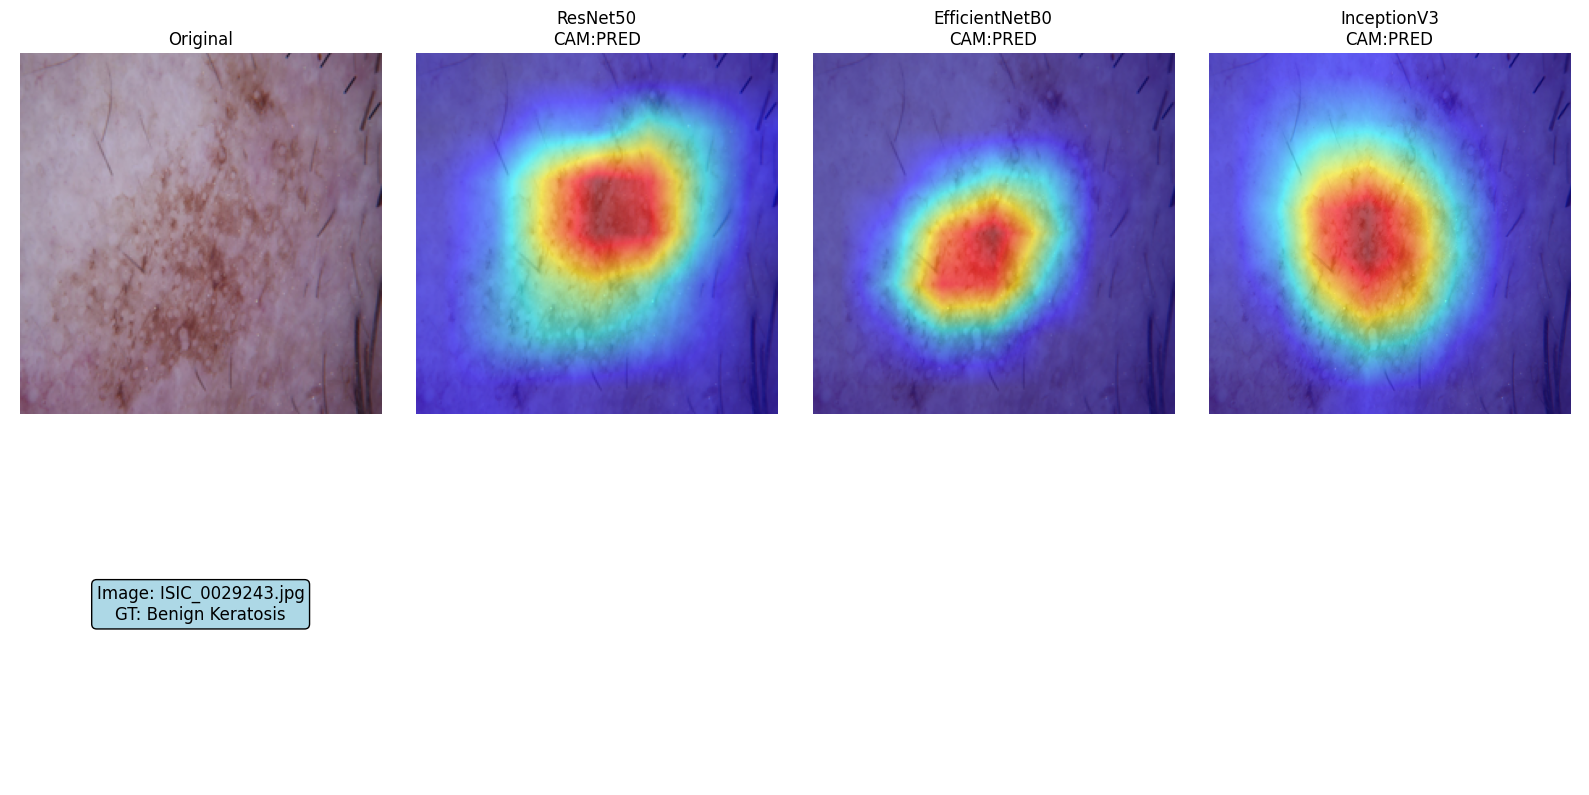


Image: ISIC_0033933.jpg
GT: Vascular Lesion
ResNet50         Pred: Actinic Keratoses       Conf: 0.553  Top-3: Actinic Keratoses (0.553), Vascular Lesion (0.436), Benign Keratosis (0.009)
EfficientNetB0   Pred: Vascular Lesion         Conf: 0.912  Top-3: Vascular Lesion (0.912), Actinic Keratoses (0.083), Benign Keratosis (0.004)
InceptionV3      Pred: Vascular Lesion         Conf: 0.539  Top-3: Vascular Lesion (0.539), Actinic Keratoses (0.412), Benign Keratosis (0.046)
Saved: /kaggle/working/gradcam_outputs/gradcam_25_ISIC_0033933.jpg.png


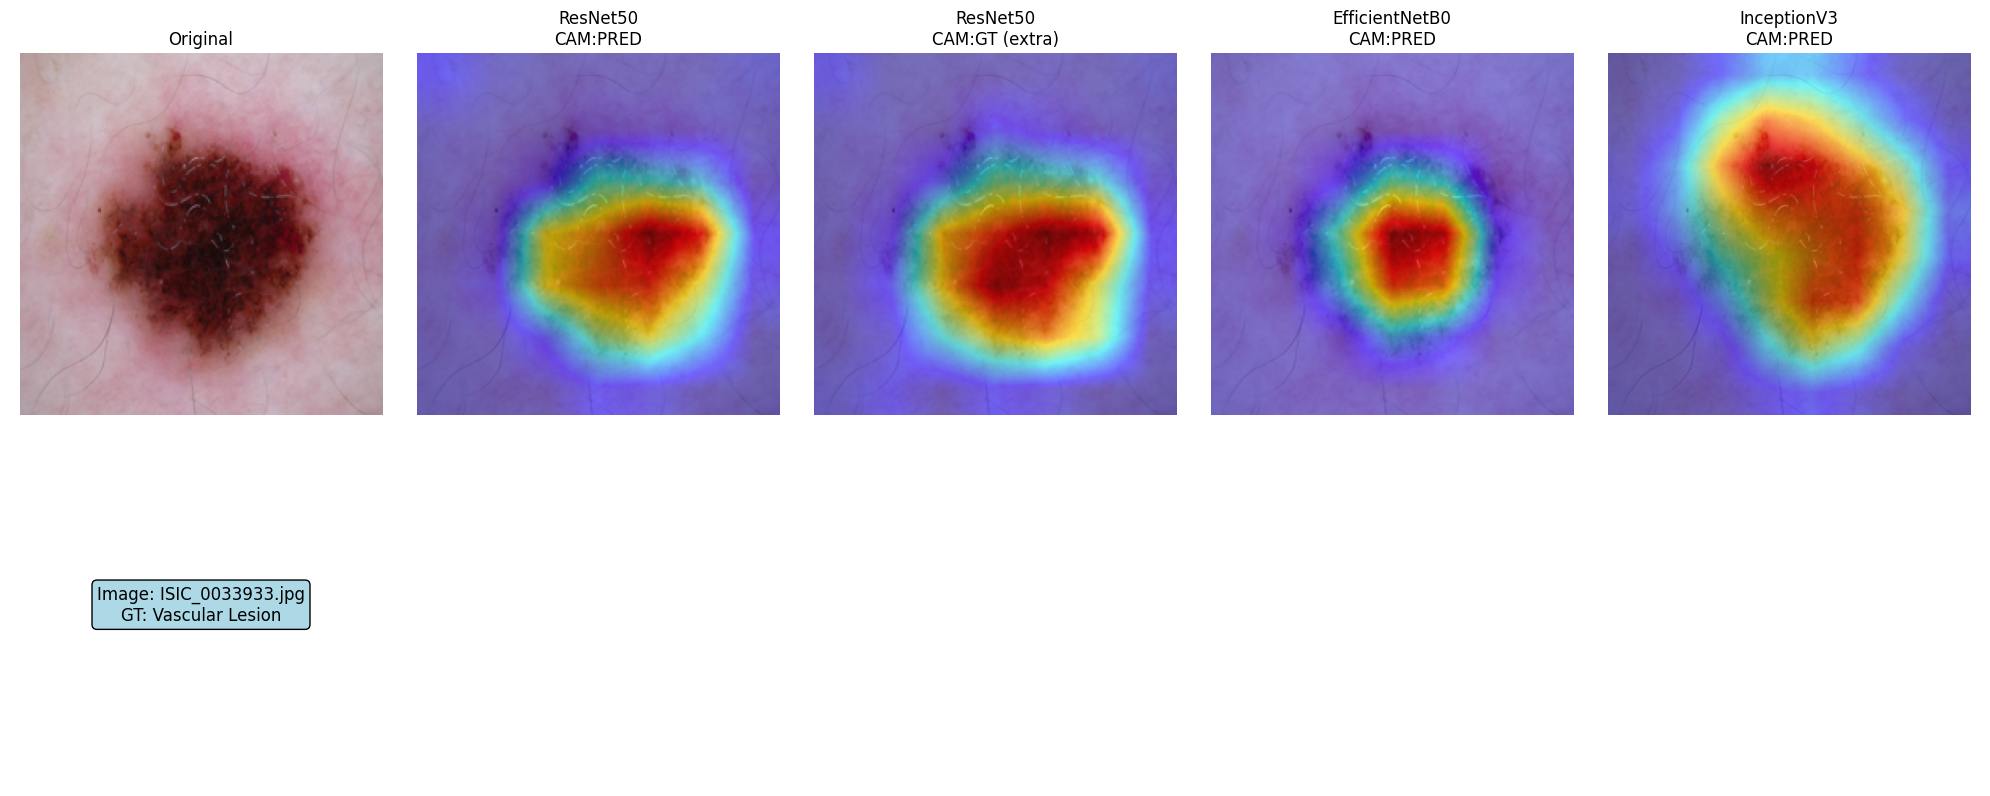


✅ Grad-CAM cell finished. No retraining was done.


In [47]:
# ===================== GRAD-CAM ONLY (NO RETRAIN) =====================
import os, glob, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# ---- CONFIG (edit as you want) ----
NUM_SAMPLES = 3                 # how many images to visualize
PICK_MODE = "random"            # "random" | "index" | "misclassified"
INDEX_TO_SHOW = 0               # used only if PICK_MODE="index"
CAM_TARGET = "pred"             # "pred" | "gt"
SHOW_GT_CAM_IF_WRONG = True     # new feature: if model wrong, also show GT-target cam
TOPK = 3                        # show top-k probs
SAVE_IMAGES = True
OUT_DIR = "/kaggle/working/gradcam_outputs"
# -----------------------------------

os.makedirs(OUT_DIR, exist_ok=True)

# ---- Safety: Grad-CAM availability ----
HAS_GRADCAM = True
try:
    from pytorch_grad_cam import GradCAM
    from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
    from pytorch_grad_cam.utils.image import show_cam_on_image
except Exception as e:
    HAS_GRADCAM = False
    print("⚠️ Grad-CAM not available:", e)

# ---- Ensure models are loaded (NO training) ----
def _ensure_models_loaded():
    # use your existing loader functions
    if "get_improved_models" in globals():
        md = get_improved_models()
        return md
    if "load_improved_models" in globals():
        nc = 7
        if "MELANOMA_CLASS_NAMES" in globals():
            try: nc = len(MELANOMA_CLASS_NAMES)
            except: pass
        md = load_improved_models(num_classes=nc)
        return md
    raise NameError("Model loading functions not found. Run cells defining model classes + load_improved_models().")

models_dict = _ensure_models_loaded()
if not models_dict:
    raise RuntimeError(
        "No models loaded. Make sure .pth files exist in /kaggle/working (or current directory).\n"
        "Expected: improved_resnet50_skin.pth, improved_efficientnetb0_skin.pth, improved_inceptionv3_skin.pth"
    )

print("Loaded models:", list(models_dict.keys()))

# ---- Load test_df (NO training) ----
def _load_test_df():
    if os.path.exists("test_data.csv"):
        df = pd.read_csv("test_data.csv")
        if {"image_path", "label"}.issubset(df.columns):
            return df.reset_index(drop=True)
    # fallback: use full df
    if "load_files" in globals():
        df, _, _ = load_files()
        return df.sample(n=min(1000, len(df)), random_state=42).reset_index(drop=True)
    raise FileNotFoundError("test_data.csv not found and load_files() not available.")

test_df = _load_test_df()
print("Test samples available:", len(test_df))

# ---- Helpers (use your earlier ones if present) ----
def _get_val_transform(model_name):
    if "get_val_transform" in globals():
        return get_val_transform(model_name)
    # fallback mapping
    if model_name == "InceptionV3":
        return VAL_TRANSFORM_299
    return VAL_TRANSFORM_224

def _get_target_layer(model_name, model):
    if "get_target_layer" in globals():
        return get_target_layer(model_name, model)
    # fallback mapping (matches your notebook)
    if model_name == "ResNet50":
        return model.backbone.layer4[-1]
    if model_name == "EfficientNetB0":
        return model.backbone.features[-1]
    if model_name == "InceptionV3":
        return model.backbone.Mixed_7c
    raise ValueError("Unknown model_name for target layer:", model_name)

def _gradcam(model, model_name, input_tensor, class_idx, pil_img):
    if not HAS_GRADCAM:
        return None, None
    target_layer = _get_target_layer(model_name, model)
    cam = GradCAM(model=model, target_layers=[target_layer])
    targets = [ClassifierOutputTarget(int(class_idx))]
    grayscale_cam = cam(input_tensor=input_tensor, targets=targets)[0]

    # Resize original image to match transform size
    tr = _get_val_transform(model_name)
    size = tr.transforms[0].size
    if isinstance(size, int):
        base = np.array(pil_img.resize((size, size))).astype(np.float32) / 255.0
    else:
        base = np.array(pil_img.resize(size)).astype(np.float32) / 255.0

    viz = show_cam_on_image(base, grayscale_cam, use_rgb=True)
    return base, viz

def _topk_str(probs, k=3):
    idxs = np.argsort(-probs)[:k]
    parts = []
    for i in idxs:
        name = MELANOMA_CLASS_NAMES[i] if "MELANOMA_CLASS_NAMES" in globals() and i < len(MELANOMA_CLASS_NAMES) else str(i)
        parts.append(f"{name} ({probs[i]:.3f})")
    return ", ".join(parts)

def _plot_grid(original, cams, titles, meta_text, save_path=None):
    n = len(cams)
    fig, axes = plt.subplots(2, n+1, figsize=(4*(n+1), 8))
    axes[0,0].imshow(original)
    axes[0,0].set_title("Original")
    axes[0,0].axis("off")
    axes[1,0].text(0.5, 0.5, meta_text, ha="center", va="center", fontsize=12,
                   bbox=dict(boxstyle="round,pad=0.3", facecolor="lightblue"))
    axes[1,0].axis("off")

    for i in range(n):
        axes[0,i+1].imshow(cams[i])
        axes[0,i+1].set_title(titles[i])
        axes[0,i+1].axis("off")
        axes[1,i+1].axis("off")

    plt.tight_layout()
    if save_path is not None:
        fig.savefig(save_path, dpi=200, bbox_inches="tight")
        print("Saved:", save_path)
    plt.show()

# ---- Pick indices ----
def _pick_indices():
    if PICK_MODE == "index":
        return [max(0, min(INDEX_TO_SHOW, len(test_df)-1))]

    if PICK_MODE == "misclassified":
        # Light search for one misclassified sample (no full eval)
        max_search = min(300, len(test_df))
        for j in range(max_search):
            row = test_df.iloc[j]
            pil_img = Image.open(row["image_path"]).convert("RGB")
            gt = int(row["label"])
            # check any one model misclassifies
            for mn, m in models_dict.items():
                x = _get_val_transform(mn)(pil_img).unsqueeze(0).to(device)
                with torch.no_grad():
                    out = m(x)
                    p = torch.softmax(out, dim=1).cpu().numpy()[0]
                if int(np.argmax(p)) != gt:
                    return [j]
        # fallback random
        return random.sample(range(len(test_df)), k=min(NUM_SAMPLES, len(test_df)))

    # default random
    return random.sample(range(len(test_df)), k=min(NUM_SAMPLES, len(test_df)))

indices = _pick_indices()
print("Selected indices:", indices)

# ---- Run Grad-CAM on selected images ----
for idx in indices:
    row = test_df.iloc[idx]
    img_path = row["image_path"]
    gt = int(row["label"]) if "label" in row else None

    pil_img = Image.open(img_path).convert("RGB")
    base_original = np.array(pil_img.resize((224,224))).astype(np.float32)/255.0

    gt_name = MELANOMA_CLASS_NAMES[gt] if gt is not None and "MELANOMA_CLASS_NAMES" in globals() and gt < len(MELANOMA_CLASS_NAMES) else str(gt)
    header = f"Image: {os.path.basename(img_path)}\nGT: {gt_name}"

    cams = []
    titles = []

    print("\n" + "="*80)
    print(header)
    print("="*80)

    for model_name, model in models_dict.items():
        tr = _get_val_transform(model_name)
        x = tr(pil_img).unsqueeze(0).to(device)

        with torch.no_grad():
            out = model(x)
            probs = torch.softmax(out, dim=1).cpu().numpy()[0]
        pred = int(np.argmax(probs))
        pred_name = MELANOMA_CLASS_NAMES[pred] if "MELANOMA_CLASS_NAMES" in globals() and pred < len(MELANOMA_CLASS_NAMES) else str(pred)

        print(f"{model_name:15}  Pred: {pred_name:22}  Conf: {probs[pred]:.3f}  Top-{TOPK}: {_topk_str(probs, TOPK)}")

        # CAM target
        if CAM_TARGET == "gt" and gt is not None:
            target_idx = gt
            tag = "GT"
        else:
            target_idx = pred
            tag = "PRED"

        _, viz = _gradcam(model, model_name, x, target_idx, pil_img)
        if viz is not None:
            cams.append(viz)
            titles.append(f"{model_name}\nCAM:{tag}")

        # NEW FEATURE: if wrong, also show GT-cam
        if SHOW_GT_CAM_IF_WRONG and gt is not None and pred != gt and HAS_GRADCAM:
            _, viz2 = _gradcam(model, model_name, x, gt, pil_img)
            if viz2 is not None:
                cams.append(viz2)
                titles.append(f"{model_name}\nCAM:GT (extra)")

    save_path = None
    if SAVE_IMAGES:
        save_path = os.path.join(OUT_DIR, f"gradcam_{idx}_{os.path.basename(img_path)}.png")

    if cams:
        _plot_grid(base_original, cams, titles, header, save_path=save_path)
    else:
        print("No Grad-CAM visualizations produced (package missing or target layer issue).")

print("\n✅ Grad-CAM cell finished. No retraining was done.")

In [46]:
# # Main execution function
# def run_complete_evaluation():
#     """Run the complete training and evaluation pipeline"""
    
#     print("Starting complete SkinScanAI evaluation pipeline...")
    
#     # Step 1: Train models
#     print("Step 1: Training models for 5 epochs...")
#     # training_results, test_df = train_and_save_improved_models()
    
#     # Step 2: Comprehensive evaluation
#     print("\nStep 2: Running comprehensive evaluation...")
#     evaluation_results, detailed_results = comprehensive_model_evaluation(
#         test_df=test_df, 
#         num_random_images=10, 
#         show_gradcam=True
#     )
    
#     # Step 3: Training vs Testing comparison
#     print("\n" + "="*80)
#     print("TRAINING VS TESTING COMPARISON")
#     print("="*80)
    
#     print(f"{'Model':<15} {'Train Val Acc':<15} {'Test Accuracy':<15} {'Difference':<12}")
#     print("-" * 70)
    
#     for model_name in training_results.keys():
#         if model_name in evaluation_results:
#             train_acc = training_results[model_name]['best_val_acc']
#             test_acc = evaluation_results[model_name]['accuracy']
#             difference = test_acc - train_acc
            
#             print(f"{model_name:<15} {train_acc:<15.2f} {test_acc:<15.2f} {difference:<12.2f}")
    
#     print("\nEvaluation complete!")
#     return training_results, evaluation_results, detailed_results

# # Execute the complete pipeline
# if __name__ == "__main__":
#     training_results, evaluation_results, detailed_results = run_complete_evaluation()

Total samples: 10015

Class distribution:
0: Melanocytic Nevus: 327 samples
1: Melanoma: 514 samples
2: Benign Keratosis: 1099 samples
3: Basal Cell Carcinoma: 115 samples
4: Actinic Keratoses: 1113 samples
5: Vascular Lesion: 6705 samples
6: Dermatofibroma: 142 samples

Training set size: 7210
Validation set size: 2003
Test set size: 802

Training ResNet50
Starting training for ResNet50
Training samples: 10017
Validation samples: 2003
Training ResNet50...


Epoch 1/5 [Train]:   0%|          | 0/627 [00:00<?, ?it/s]

KeyboardInterrupt: 